# Predicting Brain Stroke Using k-Nearest Neigbors (KNN), Logistic Regression and Support Vector Machine(SVM)

### Project Goals
Develop a machine learning model to predict customer churn risk using the k-Nearest Neighbors (KNN), Logistic Regression, and Support Vector Machine (SVM) models, and compare their performance.

This project, "Predicting Brain Stroke Using Machine Learning," was developed by the following students:

Andrei Raagas

Chavy Martin B. Tapuyao

Luzinda Niña Panong

Nathaniel Zaragosa

## Step 1: Setting Up the Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
import warnings

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                           roc_curve, roc_auc_score, precision_recall_curve,
                           average_precision_score)

This environment setup ensures we have all necessary tools for:
- Data preprocessing and cleaning
- Exploratory data analysis
- Visualization
- Model training and testing
- Performance evaluation and visualization

## Step 2: Exploratory Data Analysis (EDA)

Load and explore the dataset to understand its structure, identify missing values, and examine relationships between variables. This helps in selecting the most relevant features for the brain stroke prediction model.

#### 2.1 Load the Dataset

In [2]:
df = pd.read_csv('full_data.csv')
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [3]:
shape = df.shape

# Print the shape
print(f"DataFrame shape: {shape}")
print(f"Rows: {shape[0]}")
print(f"Columns: {shape[1]}")

# Or more directly
print(f"The DataFrame has {df.shape[0]} rows and {df.shape[1]} columns")

DataFrame shape: (4981, 11)
Rows: 4981
Columns: 11
The DataFrame has 4981 rows and 11 columns


#### 2.2 Display the Column Names

In [4]:
for columns in df.columns:
  print(columns)

gender
age
hypertension
heart_disease
ever_married
work_type
Residence_type
avg_glucose_level
bmi
smoking_status
stroke


#### 2.3 Display the Summary Statistics

In [5]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000
mean,43.419859,0.096165,0.055210,105.943562,28.498173,0.049789
std,22.662755,0.294848,0.228412,45.075373,6.790464,0.217531
min,0.080000,0.000000,0.000000,55.120000,14.000000,0.000000
25%,25.000000,0.000000,0.000000,77.230000,23.700000,0.000000
50%,45.000000,0.000000,0.000000,91.850000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,113.860000,32.600000,0.000000
max,82.000000,1.000000,1.000000,271.740000,48.900000,1.000000


#### 2.4 Checking the Data Types

Let's also check the data types of each column inorder for us to identify which columns are numerical and which are categorical.

This step is crucial for understanding how different features should be handled in preprocessing.

In [6]:
df.dtypes

gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

#### 2.5 Checking For Missing Values

In [7]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

Since our dataset has no missing values, data imputation is not required.

In [8]:
df = df.drop(["ever_married", "work_type", "Residence_type"], axis =1)

Removing "ever_married", "work_type", and "Residence_type" is fine because these features show little to no clear correlation with stroke occurrence in the data, so they likely don’t contribute meaningfully to predicting whether a person had a stroke or not.

## Step 3: Visualization

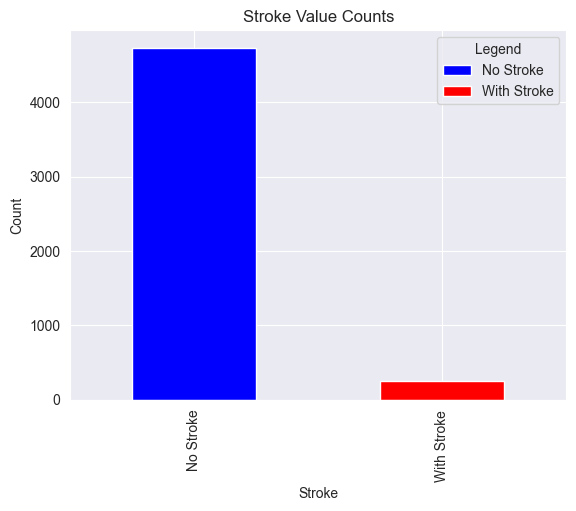

In [9]:
counts = df['stroke'].value_counts()

# Define colors: 0 = blue (No Stroke), 1 = red (With Stroke)
colors = ['blue' if idx == 0 else 'red' for idx in counts.index]

bars = counts.plot(kind='bar', color=colors)

plt.title('Stroke Value Counts')
plt.xlabel('Stroke')
plt.ylabel('Count')
plt.xticks([0, 1], ['No Stroke', 'With Stroke'])

# Create a color-based legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='blue', label='No Stroke'),
    Patch(facecolor='red', label='With Stroke')
]
plt.legend(handles=legend_elements, title='Legend')

plt.show()


Having a much higher number of non-stroke cases than stroke cases can lead to an imbalanced dataset, making it harder for a model to accurately detect strokes because it may be biased toward predicting the majority class.

## Step 4: Data Preprocessing


Before we train our model, we need to ensure that all data are preprocessed.

In [10]:
gender = df['gender'].unique()    
smoking_status = df['smoking_status'].unique() 

print(gender)  
print(smoking_status) 

['Male' 'Female']
['formerly smoked' 'never smoked' 'smokes' 'Unknown']


####  4.1 One-Hot Encoding for Nominal Variables

In our dataset, the categorical features are 'gender' and 'smoking_status', which have no inherent order. Therefore, we will apply one-hot encoding to these variables.


In [11]:
nominal_columns = [col for col in ['gender','smoking_status'] if col in df.columns]

df = pd.get_dummies(df, columns = nominal_columns, drop_first=True)
df

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,True,False,False
1,80.0,0,1,105.92,32.5,1,True,False,True,False
2,49.0,0,0,171.23,34.4,1,False,False,False,True
3,79.0,1,0,174.12,24.0,1,False,False,True,False
4,81.0,0,0,186.21,29.0,1,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...
4976,41.0,0,0,70.15,29.8,0,True,True,False,False
4977,40.0,0,0,191.15,31.1,0,True,False,False,True
4978,45.0,1,0,95.02,31.8,0,False,False,False,True
4979,40.0,0,0,83.94,30.0,0,True,False,False,True


In [12]:
df.columns

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'stroke', 'gender_Male', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes'],
      dtype='object')

In [13]:
df.dtypes

age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
stroke                              int64
gender_Male                          bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
dtype: object

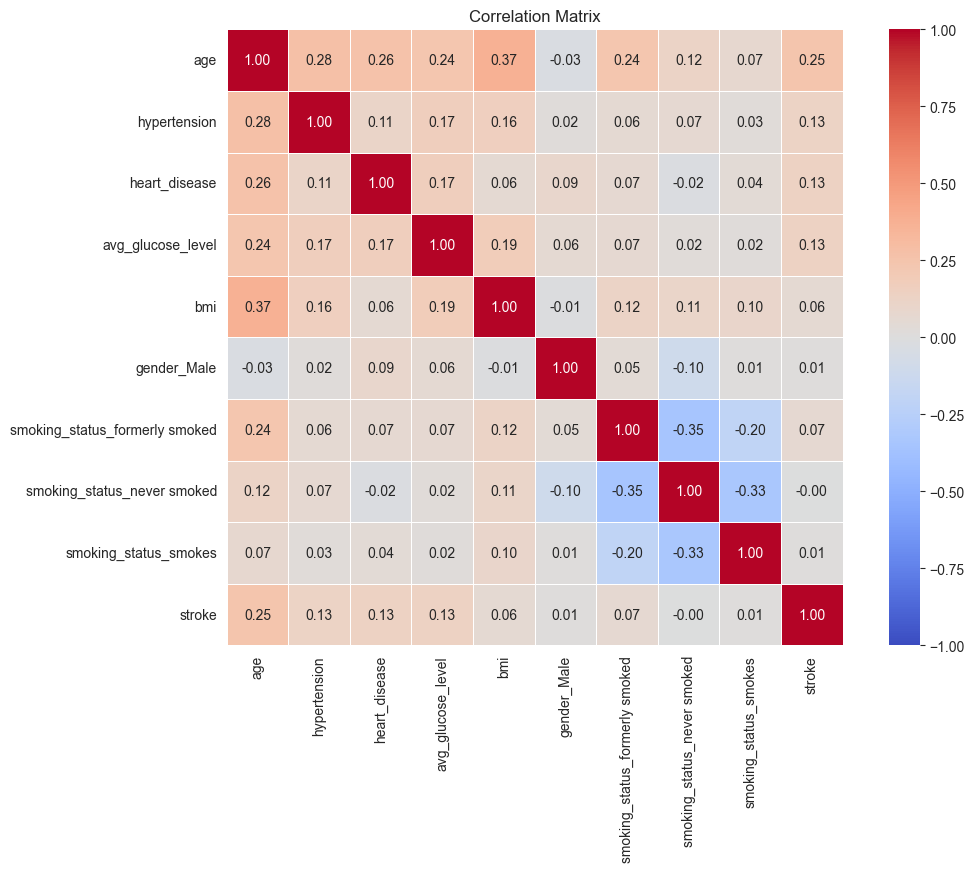

In [14]:
custom_order = [
  'age',
  'hypertension',
  'heart_disease',
  'avg_glucose_level',
  'bmi',
  'gender_Male',
  'smoking_status_formerly smoked',
  'smoking_status_never smoked',
  'smoking_status_smokes',
  'stroke'
]

valid_order = [col for col in custom_order if col in df.columns]

corr_margin = df[valid_order].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_margin,
    annot=True, 
    fmt=".2f",
    cmap='coolwarm', 
    cbar=True,
    square=True,
    linewidths=0.5,
    vmin=-1, 
    vmax=1   
  )
plt.title('Correlation Matrix')
plt.show()

#### 4.2 Bringing Features on the same scale

all numerical features to the same scale using StandarScaler.

In [15]:
feature_columns = [col for col in df.columns if col != "stroke"]

scaler = StandardScaler()
df[feature_columns] = scaler.fit_transform(df[feature_columns])

df

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1.040584,-0.326186,4.136753,2.723411,1.193238,1,1.183909,2.178325,-0.764717,-0.429584
1,1.614270,-0.326186,4.136753,-0.000523,0.589390,1,1.183909,-0.459068,1.307674,-0.429584
2,0.246250,-0.326186,-0.241735,1.448529,0.869222,1,-0.844660,-0.459068,-0.764717,2.327835
3,1.570141,3.065738,-0.241735,1.512650,-0.662492,1,-0.844660,-0.459068,1.307674,-0.429584
4,1.658400,-0.326186,-0.241735,1.780895,0.073909,1,1.183909,2.178325,-0.764717,-0.429584
...,...,...,...,...,...,...,...,...,...,...
4976,-0.106788,-0.326186,-0.241735,-0.794162,0.191733,0,1.183909,2.178325,-0.764717,-0.429584
4977,-0.150917,-0.326186,-0.241735,1.890500,0.383197,0,1.183909,-0.459068,-0.764717,2.327835
4978,0.069731,3.065738,-0.241735,-0.242364,0.486294,0,-0.844660,-0.459068,-0.764717,2.327835
4979,-0.150917,-0.326186,-0.241735,-0.488199,0.221189,0,1.183909,-0.459068,-0.764717,2.327835


Now that we are done with data preprocessing, the dataset is ready for model training and testing.


## Step 5: Training and Testing Model

#### 5.1 K-Nearest Neighbors (KNN) Model

In [16]:
# Define target and features
target = "stroke" 
X = df.drop(columns=[target])
y = df[target]

# Define ranges
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
neighbors_range = range(1, 10)

# To store the best overall model
best_overall_model = None
highest_avg_test_acc = 0

# Iterate over test sizes
for test_size in test_sizes:
    train_scores = []
    test_scores = []
    sum_random_states = 0
    count = 0
    best_model = None
    lowest_balance = float("inf")

    for random_state in random_states:
        for n_neighbors in neighbors_range:
            # Split data
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=random_state
            )

            clf = KNeighborsClassifier(n_neighbors=n_neighbors)
            clf.fit(X_train, y_train)

            train_acc = clf.score(X_train, y_train)
            test_acc = clf.score(X_test, y_test)

            # Skip overfitted models
            if test_acc > train_acc:
                continue

            balance_score = abs(train_acc - test_acc)

            if balance_score < lowest_balance:
                lowest_balance = balance_score
                best_model = {
                    "test_size": test_size,
                    "n_neighbors": n_neighbors,
                    "random_state": random_state,
                    "train_acc": train_acc,
                    "test_acc": test_acc,
                }

            train_scores.append(train_acc)
            test_scores.append(test_acc)
            sum_random_states += random_state
            count += 1

    if count > 0:
        avg_train_acc = np.mean(train_scores)
        avg_test_acc = np.mean(test_scores)
        avg_random_state = round(sum_random_states / count)  # Rounded to whole number
        best_neighbors = best_model["n_neighbors"]

        # Update best overall model if this test size has a higher average test accuracy
        if avg_test_acc > highest_avg_test_acc:
            highest_avg_test_acc = avg_test_acc
            best_overall_model = {
                "Test Size": test_size,
                "Average Training Accuracy": avg_train_acc,
                "Average Test Accuracy": avg_test_acc,
                "Best Number of Neighbors (k)": best_neighbors
    }
    else:
        avg_train_acc = avg_test_acc = avg_random_state = 0
        best_neighbors = None

    # Print results in the old format
    print(f"\nTest Size : {test_size}")
    print(f"Average Training Accuracy : {avg_train_acc :.6f}")
    print(f"Average Test Accuracy : {avg_test_acc :.6f}")

# Display the best overall model
if best_overall_model:
    print("\n=== Best Average Model Overall ===")
    for key, value in best_overall_model.items():
        print(f"{key} : {value :.6f}")


Test Size : 0.15
Average Training Accuracy : 0.960350
Average Test Accuracy : 0.937652

Test Size : 0.2
Average Training Accuracy : 0.959568
Average Test Accuracy : 0.939086

Test Size : 0.25
Average Training Accuracy : 0.959970
Average Test Accuracy : 0.940171

Test Size : 0.3
Average Training Accuracy : 0.960235
Average Test Accuracy : 0.940478

=== Best Average Model Overall ===
Test Size : 0.300000
Average Training Accuracy : 0.960235
Average Test Accuracy : 0.940478
Best Number of Neighbors (k) : 7.000000


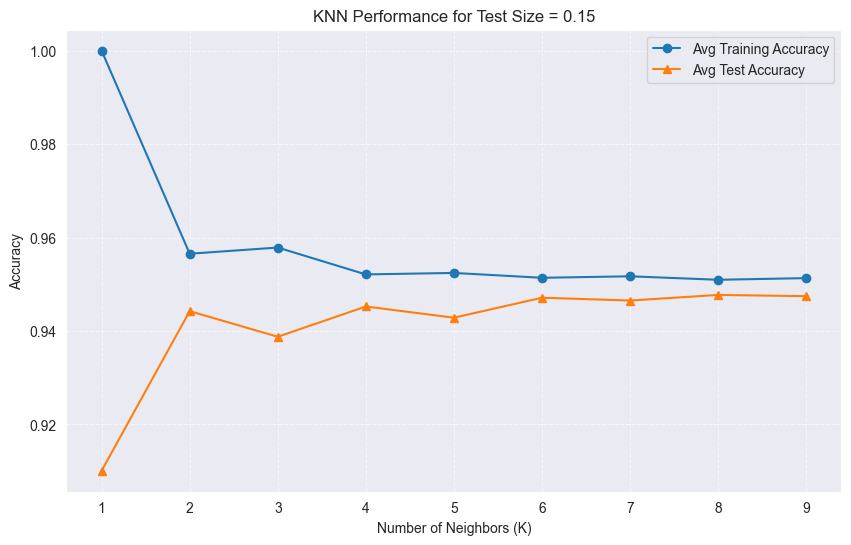

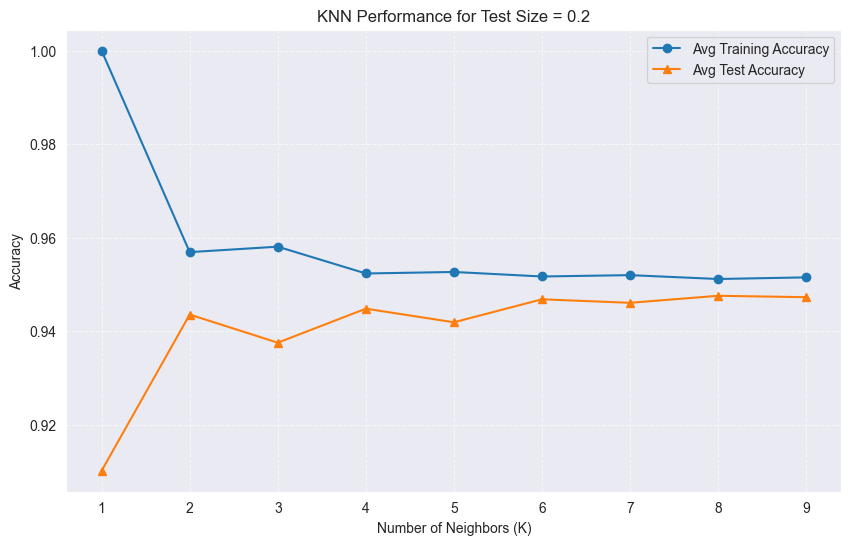

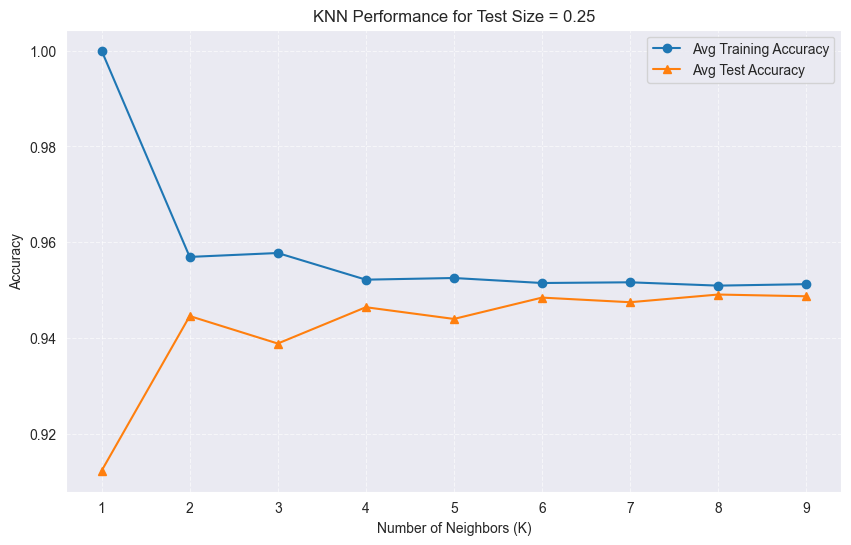

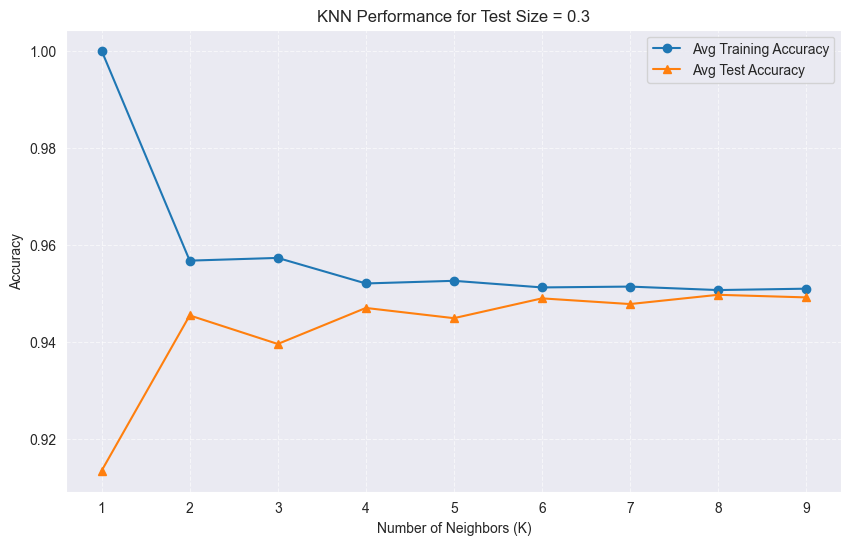

In [17]:
# Define target variable
target = "stroke"
X = df.drop(columns=[target])
y = df[target]

# Define parameters
split_ratios = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
neighbors_range = range(1, 10)

# Store results
results = []

# Iterate over different test sizes, random states, and neighbor values
for test_size in split_ratios:
    for random_state in random_states:
        for n_neighbors in neighbors_range:
            # Split data with fixed validation size at 15%
            X_train, X_test, y_train, y_test = train_test_split(
                X,
                y,
                test_size=test_size,
                random_state=random_state
            )

            # Train KNN model
            clf = KNeighborsClassifier(n_neighbors=n_neighbors)
            clf.fit(X_train, y_train)

            # Compute accuracies
            train_acc = clf.score(X_train, y_train)
            test_acc = clf.score(X_test, y_test)

            # Save results
            results.append((test_size, random_state, n_neighbors, train_acc, test_acc))

# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=["Test Size", "Random State", "Neighbors", "Train Acc", "Test Acc"])

# Average results across random states for each test size and K value
avg_results_df = results_df.groupby(['Test Size', 'Neighbors'])[['Train Acc', 'Test Acc']].mean().reset_index()

# Plot for each test size
for test_size in split_ratios:
    subset = avg_results_df[avg_results_df['Test Size'] == test_size]
    plt.figure(figsize=(10, 6))
    plt.plot(subset['Neighbors'], subset['Train Acc'], label='Avg Training Accuracy', marker='o')
    plt.plot(subset['Neighbors'], subset['Test Acc'], label='Avg Test Accuracy', marker='^')
    plt.xlabel('Number of Neighbors (K)')
    plt.ylabel('Accuracy')
    plt.title(f'KNN Performance for Test Size = {test_size}')
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.xticks(subset['Neighbors'])  # Ensure all K values appear
    plt.show()


Test Size : 0.15
Average Training Accuracy : 0.940957
Average Test Accuracy : 0.819682

Test Size : 0.2
Average Training Accuracy : 0.940576
Average Test Accuracy : 0.818940

Test Size : 0.25
Average Training Accuracy : 0.941151
Average Test Accuracy : 0.820011

Test Size : 0.3
Average Training Accuracy : 0.940380
Average Test Accuracy : 0.819569

=== Best Average Model Overall ===
Test Size : 0.250000
Average Training Accuracy : 0.941151
Average Test Accuracy : 0.820011
Best Number of Neighbors (k) : 6.000000

=== Confusion Matrix for Best Model ===


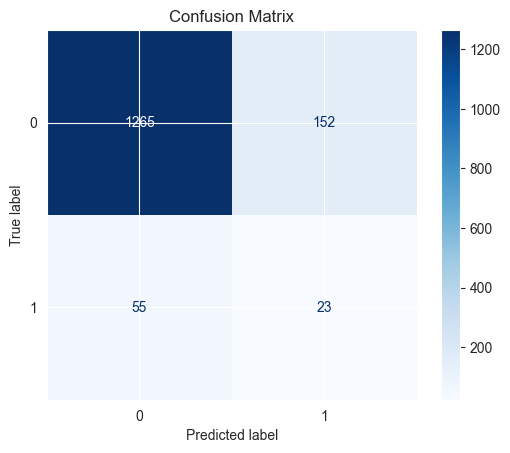

In [18]:
# Define target and features
target = "stroke"
X = df.drop(columns=[target])
y = df[target]

# Define ranges
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
neighbors_range = range(1, 10)

# Track best model overall
best_overall_model = None
highest_avg_test_acc = 0

# Store best final classifier for confusion matrix
final_best_clf = None
final_X_test = None
final_y_test = None

# Iterate over different test sizes
for test_size in test_sizes:
    train_scores = []
    test_scores = []
    sum_random_states = 0
    count = 0
    best_model = None
    lowest_balance = float("inf")

    for random_state in random_states:
        # Split data
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )

        # Apply SMOTE only on training set
        smote = SMOTE(random_state=random_state)
        X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

        for n_neighbors in neighbors_range:
            clf = KNeighborsClassifier(n_neighbors=n_neighbors)
            clf.fit(X_train_res, y_train_res)

            train_acc = clf.score(X_train_res, y_train_res)
            test_acc = clf.score(X_test, y_test)

            # Skip clearly overfitting models (allow small margin)
            if test_acc > train_acc + 0.02:
                continue

            balance_score = abs(train_acc - test_acc)

            if balance_score < lowest_balance:
                lowest_balance = balance_score
                best_model = {
                    "test_size": test_size,
                    "n_neighbors": n_neighbors,
                    "random_state": random_state,
                    "train_acc": train_acc,
                    "test_acc": test_acc,
                }
                final_best_clf = clf
                final_X_test = X_test
                final_y_test = y_test

            train_scores.append(train_acc)
            test_scores.append(test_acc)
            sum_random_states += random_state
            count += 1

    if count > 0:
        avg_train_acc = np.mean(train_scores)
        avg_test_acc = np.mean(test_scores)
        avg_random_state = round(sum_random_states / count)
        best_neighbors = best_model["n_neighbors"] if best_model else None

        print(f"\nTest Size : {test_size}")
        print(f"Average Training Accuracy : {avg_train_acc:.6f}")
        print(f"Average Test Accuracy : {avg_test_acc:.6f}")

        if avg_test_acc > highest_avg_test_acc:
            highest_avg_test_acc = avg_test_acc
            best_overall_model = {
                "Test Size": test_size,
                "Average Training Accuracy": avg_train_acc,
                "Average Test Accuracy": avg_test_acc,
                "Best Number of Neighbors (k)": best_neighbors
            }
    else:
        print(f"\nTest Size : {test_size}")
        print("No valid models found for this test size.")

# Display best overall model
if best_overall_model:
    print("\n=== Best Average Model Overall ===")
    for key, value in best_overall_model.items():
        print(f"{key} : {value:.6f}")

    # Confusion Matrix
    if final_best_clf is not None:
        print("\n=== Confusion Matrix for Best Model ===")
        y_pred = final_best_clf.predict(final_X_test)
        cm = confusion_matrix(final_y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(cmap='Blues', values_format='d')
        plt.title("Confusion Matrix")
        plt.show()
else:
    print("\nNo suitable model found across all test sizes.")

After an initial run where our model showed excellent training and testing accuracy, we recognized this could be misleading because the model might be predominantly predicting non-stroke cases due to data imbalance; to address this, we decided to employ the **Synthetic Minority Over-sampling Technique** (SMOTE), which generates synthetic examples of the minority class (stroke cases) to balance the dataset and help the model learn better from underrepresented data. We chose SMOTE instead of weight balancing because K-Nearest Neighbors (KNN) does not support class weights.

Additionally, we displayed a confusion matrix to verify whether the model was actually predicting non-stroke cases disproportionately.

#### 4.2 Logistic Regression
For the regularized (Both L2 and L1) Logistic Regression models, we are employing class weight balancing to address the dataset imbalance. Since Logistic Regression supports class weights, this approach helps the model give more importance to the minority class (stroke cases) during training without altering the data distribution. This improves the model’s ability to correctly predict underrepresented cases while still benefiting from regularization to prevent overfitting.

#### L2 Regularization


=== Testing Approach: Balanced Weights ===

=== Best Model for Balanced Weights ===
Test Size: 0.25
C Value: 10.0
Avg Training Accuracy: 0.734163
Avg Test Accuracy: 0.732504


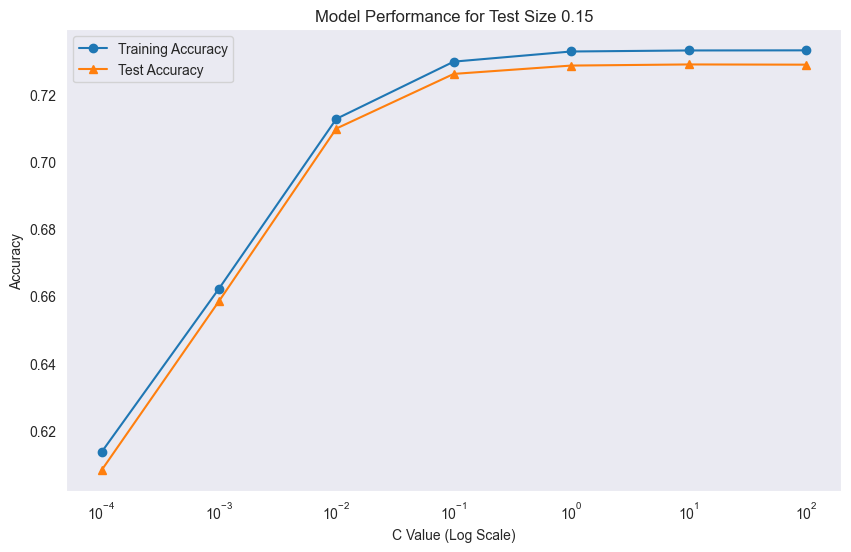

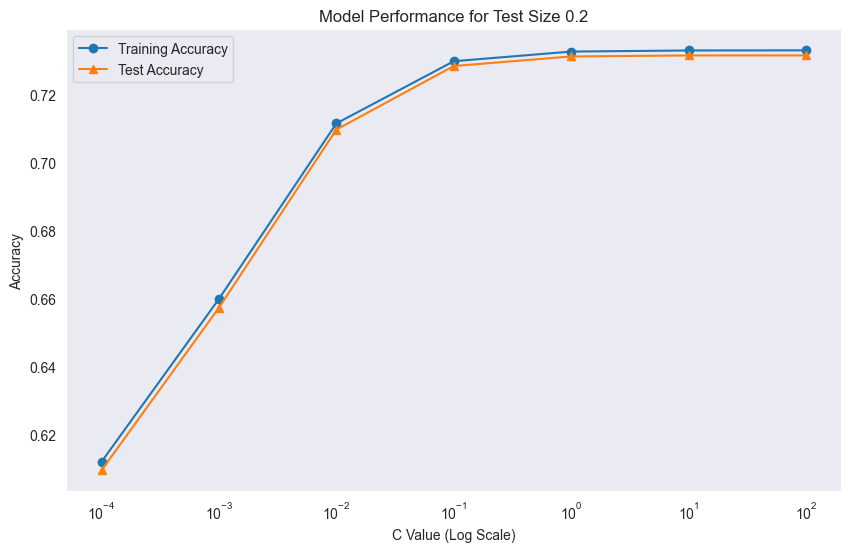

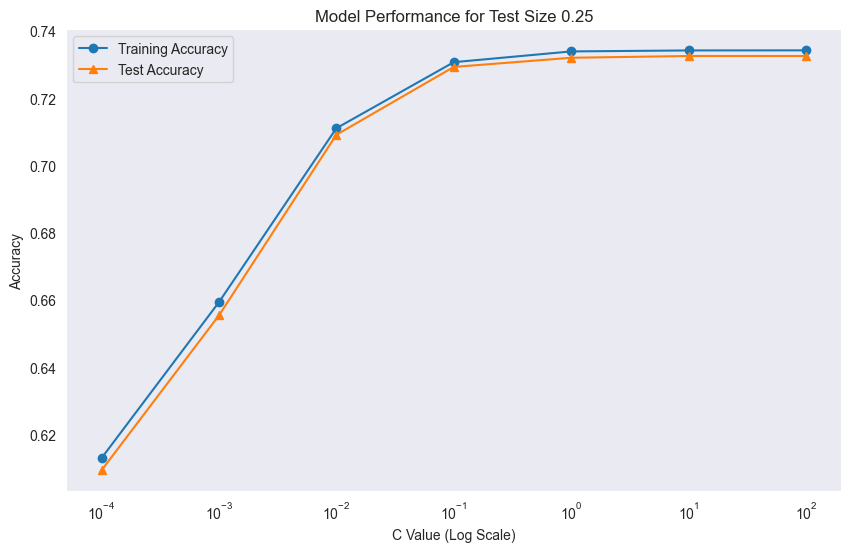

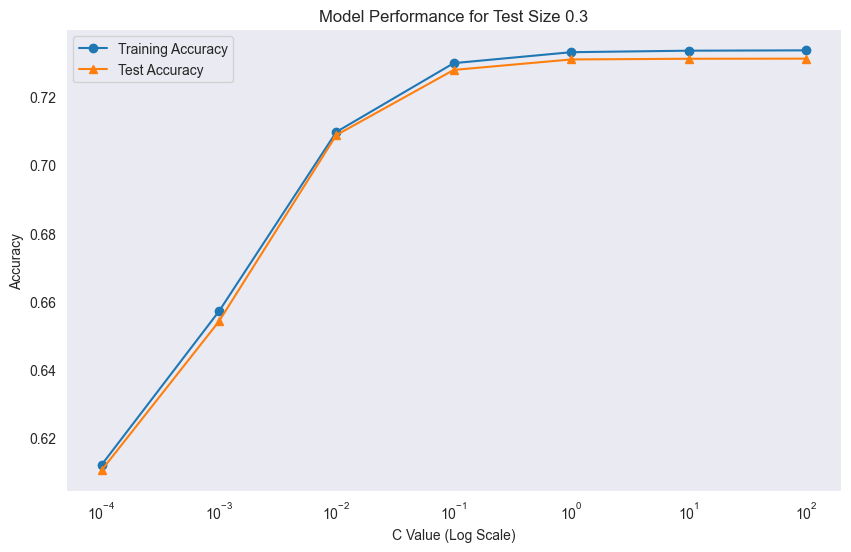

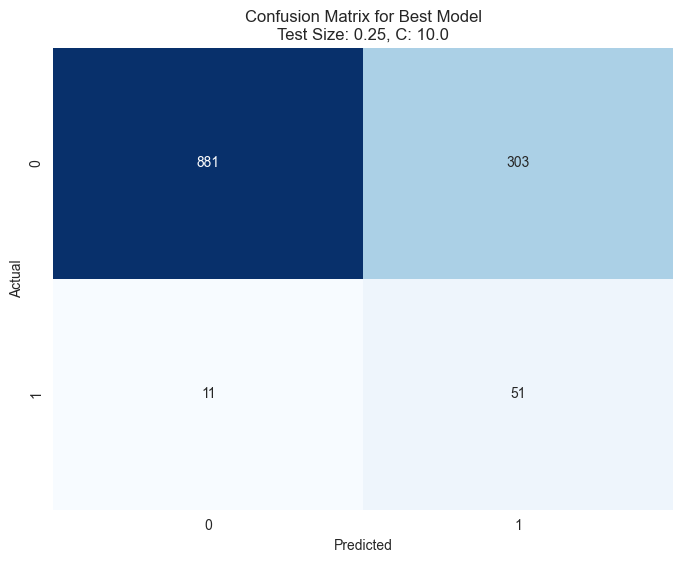


=== Confusion Matrix Values ===
[[881 303]
 [ 11  51]]


In [27]:
# Parameters
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# Only keeping the balanced weights approach
approaches = [
    {"name": "Balanced Weights", "class_weight": "balanced"},
]

# A dictionary to store best models for each approach
best_models = {}

# Loop through each approach
for approach in approaches:
    print(f"\n=== Testing Approach: {approach['name']} ===")

    # To store all results
    results = []

    # Loop over test_size and C combinations
    for test_size in test_sizes:
        for C in C_values:
            metrics = {
                'train_accuracy': [],
                'test_accuracy': []
            }

            for random_state in random_states:
                # Step 1: Split into Train and Test
                X_train, X_test, y_train, y_test = train_test_split(
                    X, y, test_size=test_size, random_state=random_state, stratify=y
                )

                # Train logistic regression with balanced weights
                model = LogisticRegression(
                    C=C,
                    penalty='l2',
                    solver='liblinear',
                    class_weight=approach["class_weight"],
                    max_iter=1000
                )
                model.fit(X_train, y_train)

                # Record metrics
                metrics['train_accuracy'].append(model.score(X_train, y_train))
                metrics['test_accuracy'].append(model.score(X_test, y_test))

            # Save average metrics
            results.append({
                'Test Size': test_size,
                'C Value': C,
                'Avg Training Accuracy': np.mean(metrics['train_accuracy']),
                'Avg Test Accuracy': np.mean(metrics['test_accuracy'])
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    # Find the best model based on test accuracy
    best_model_idx = results_df['Avg Test Accuracy'].idxmax()
    best_model = results_df.iloc[best_model_idx]

    print(f"\n=== Best Model for {approach['name']} ===")
    print(f"Test Size: {best_model['Test Size']}")
    print(f"C Value: {best_model['C Value']}")
    print(f"Avg Training Accuracy: {best_model['Avg Training Accuracy']:.6f}")
    print(f"Avg Test Accuracy: {best_model['Avg Test Accuracy']:.6f}")

    # Store best model configuration for this approach
    best_models[approach['name']] = best_model

    for test_size in test_sizes:
        subset = results_df[results_df['Test Size'] == test_size]
        plt.figure(figsize=(10, 6))
        plt.plot(subset['C Value'], subset['Avg Training Accuracy'], label='Training Accuracy', marker='o')
        plt.plot(subset['C Value'], subset['Avg Test Accuracy'], label='Test Accuracy', marker='^')
        plt.xscale('log')
        plt.xlabel('C Value (Log Scale)')
        plt.ylabel('Accuracy')
        plt.title(f'Model Performance for Test Size {test_size}')
        plt.legend()
        plt.grid()
        plt.show()

# ================ CONFUSION MATRIX FOR BEST MODEL ================
# Now that we have the best model parameters, let's create a confusion matrix

# Get the best model parameters
best_approach = list(best_models.keys())[0]  # Since there's only one approach
best_params = best_models[best_approach]
best_test_size = best_params['Test Size']
best_C = best_params['C Value']

# Create a final model with the best parameters
# Using a fixed random state for consistency
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=best_test_size, random_state=42, stratify=y
)

final_model = LogisticRegression(
    C=best_C,
    penalty='l2',
    solver='liblinear',
    class_weight="balanced",
    max_iter=1000
)
final_model.fit(X_train, y_train)

# Make predictions
y_pred = final_model.predict(X_test)

# Create and plot confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix for Best Model\nTest Size: {best_test_size}, C: {best_C}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\n=== Confusion Matrix Values ===")
print(cm)

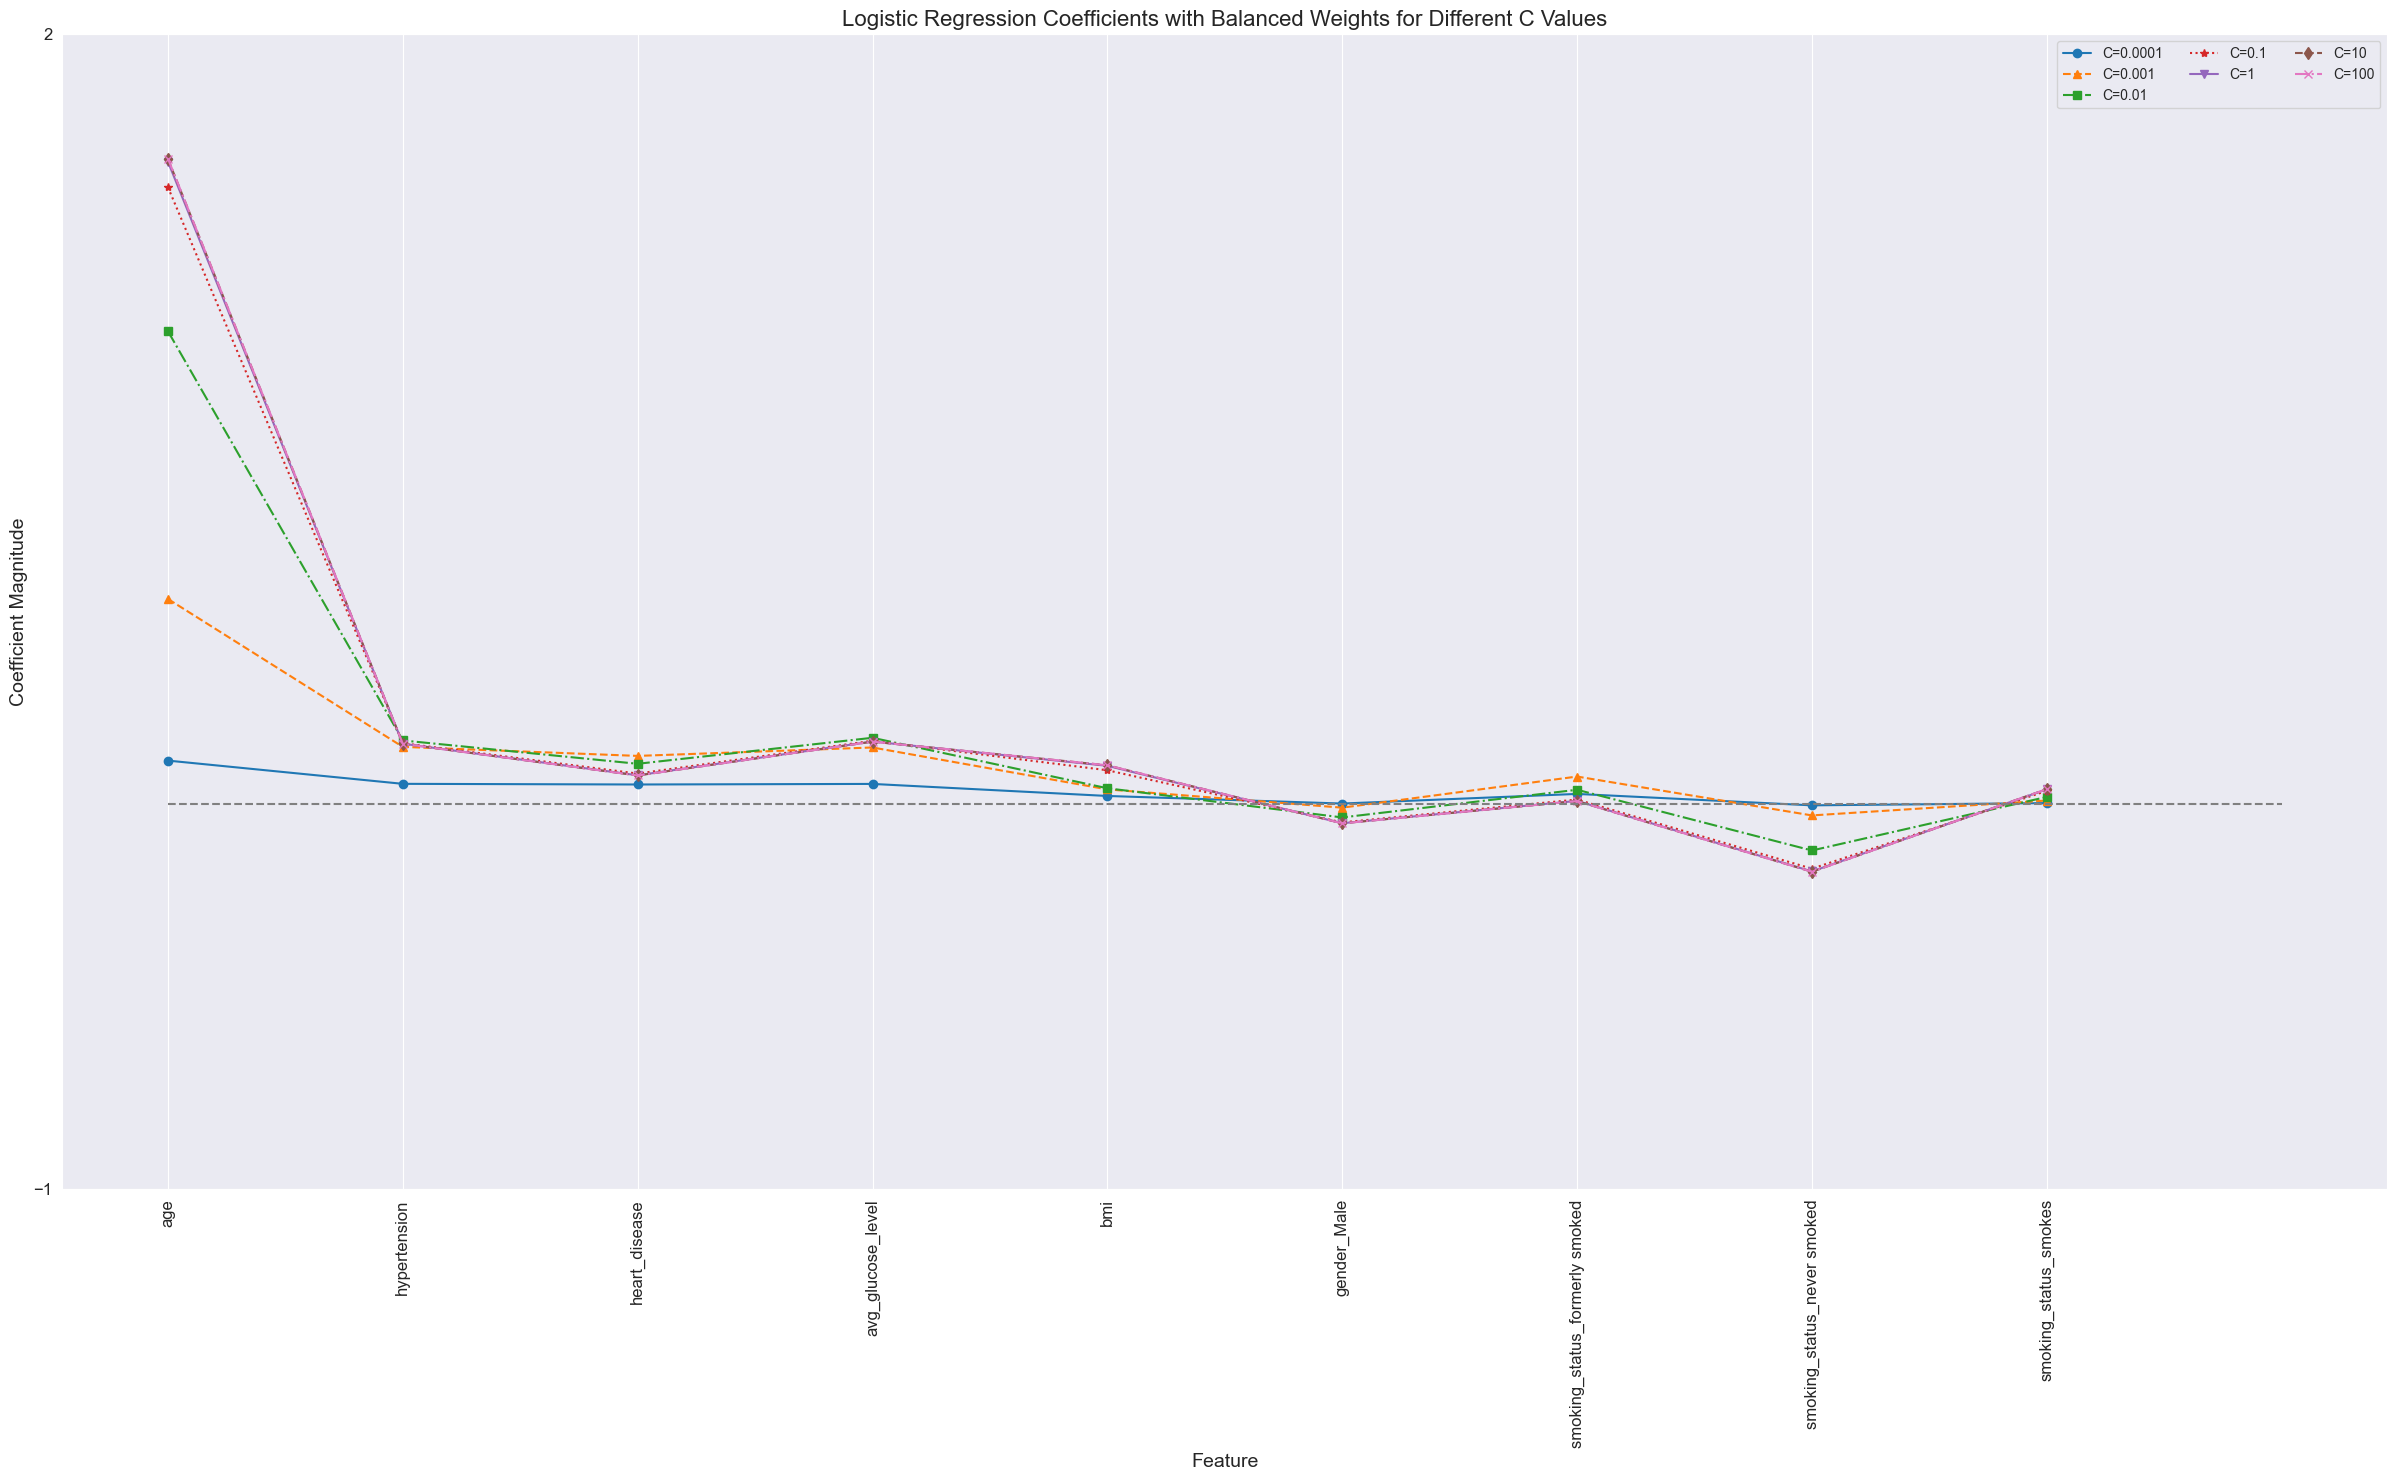

=== Top 5 Predictors (L2 Regularization with Balanced Weights) ===
1.  Feature: age
     Coefficient Weight: 1.677059
     Absolute Weight: 1.677059
     C Value: 100
2.  Feature: age
     Coefficient Weight: 1.676329
     Absolute Weight: 1.676329
     C Value: 10
3.  Feature: age
     Coefficient Weight: 1.669098
     Absolute Weight: 1.669098
     C Value: 1
4.  Feature: age
     Coefficient Weight: 1.602880
     Absolute Weight: 1.602880
     C Value: 0.1
5.  Feature: age
     Coefficient Weight: 1.228844
     Absolute Weight: 1.228844
     C Value: 0.01

=== Overall Top Predictor ===
Feature: age
Coefficient Weight of the Top Predictor: 1.677059
Absolute Weight of the Top Predictor: 1.677059
Best C Value for Top Predictor: 100

=== Comparing Weighted vs Non-Weighted Models ===


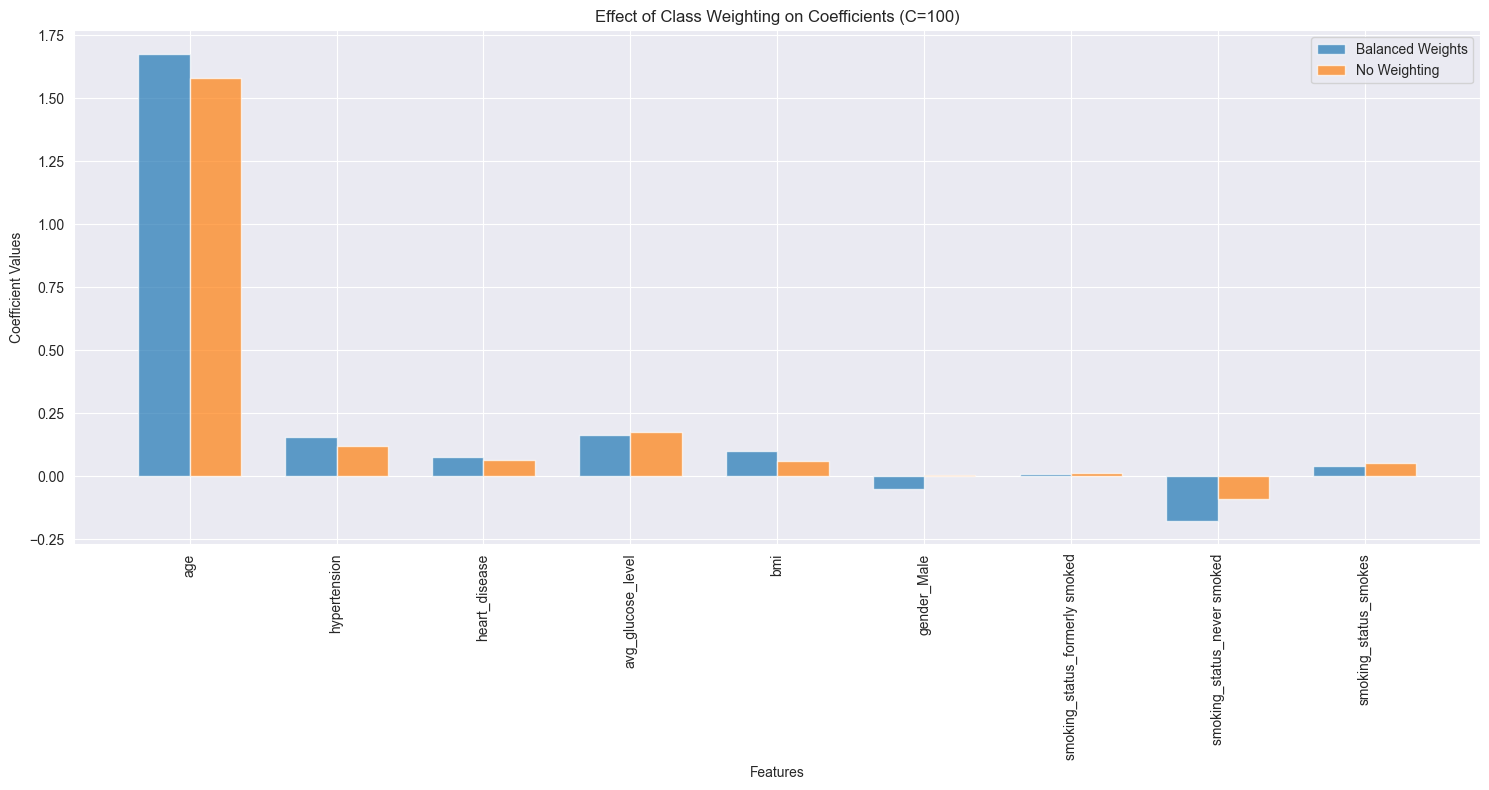

In [20]:
# Define target variable
target = "stroke"
X = df.drop(columns=[target])
y = df[target]

# Define all C values
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# Train models for all C values WITH balanced weights and store coefficients
models = {C: LogisticRegression(C=C, penalty='l2', solver="liblinear", class_weight="balanced").fit(X, y) for C in C_values}

# Create figure
fig = plt.figure(figsize=(30, 15))  # Larger figure for better visibility

# Line styles and markers for better differentiation
line_styles = ['-', '--', '-.', ':']
markers = ['o', '^', 's', '*', 'v', 'd', 'x', 'p']

for idx, (C, model) in enumerate(models.items()):
    plt.plot(model.coef_.T, f"{line_styles[idx % len(line_styles)]}{markers[idx % len(markers)]}", label=f"C={C}")

plt.xticks(range(X.shape[1]), X.columns, rotation=90, fontsize=12)  # Larger font size for readability
plt.hlines(0, 0, X.shape[1], colors='gray', linestyles='dashed')

# Adjust y-axis ticks with a step of 3
y_min, y_max = plt.ylim()
plt.yticks(np.arange(np.floor(y_min), np.ceil(y_max) + 1, 3), fontsize=12)

plt.xlabel("Feature", fontsize=14)
plt.ylabel("Coefficient Magnitude", fontsize=14)
plt.legend(loc='best', fontsize=10, ncol=3)
plt.title("Logistic Regression Coefficients with Balanced Weights for Different C Values", fontsize=16)
plt.grid(True)  # Adds a grid for better readability
plt.show()

# Find the top 5 predictors
top_predictors = []

for C, model in models.items():
    for idx, coef in enumerate(model.coef_[0]):
        top_predictors.append({
            "Feature": X.columns[idx],
            "Coefficient Weight": coef,
            "Absolute Weight": abs(coef),  # Store absolute weight
            "C Value": C
        })

# Sort predictors by absolute coefficient weight in descending order
top_predictors = sorted(top_predictors, key=lambda x: x["Absolute Weight"], reverse=True)

# Get the top 5 predictors
top_5_predictors = top_predictors[:5]

# Display the top 5 predictors
print("=== Top 5 Predictors (L2 Regularization with Balanced Weights) ===")
for i, predictor in enumerate(top_5_predictors, start=1):
    print(f"{i}.  Feature: {predictor['Feature']}")
    print(f"     Coefficient Weight: {predictor['Coefficient Weight']:.6f}")
    print(f"     Absolute Weight: {predictor['Absolute Weight']:.6f}")
    print(f"     C Value: {predictor['C Value']}")

# Display the overall top predictor
overall_top_predictor = top_5_predictors[0]
print("\n=== Overall Top Predictor ===")
print(f"Feature: {overall_top_predictor['Feature']}")
print(f"Coefficient Weight of the Top Predictor: {overall_top_predictor['Coefficient Weight']:.6f}")
print(f"Absolute Weight of the Top Predictor: {overall_top_predictor['Absolute Weight']:.6f}")
print(f"Best C Value for Top Predictor: {overall_top_predictor['C Value']}")

# Optional additional analysis: Compare weighted vs non-weighted coefficients
print("\n=== Comparing Weighted vs Non-Weighted Models ===")
# Train a non-weighted model using the best C value
best_C = overall_top_predictor['C Value']
weighted_model = models[best_C]
non_weighted_model = LogisticRegression(C=best_C, penalty='l2', solver="liblinear").fit(X, y)

# Plot comparison
plt.figure(figsize=(15, 8))
bar_width = 0.35
index = np.arange(X.shape[1])

plt.bar(index, weighted_model.coef_[0], bar_width, label='Balanced Weights', alpha=0.7)
plt.bar(index + bar_width, non_weighted_model.coef_[0], bar_width, label='No Weighting', alpha=0.7)

plt.xlabel('Features')
plt.ylabel('Coefficient Values')
plt.title(f'Effect of Class Weighting on Coefficients (C={best_C})')
plt.xticks(index + bar_width/2, X.columns, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

#### L1 Regularization


=== Testing Approach: L1 Balanced Weights ===

=== Best Model for L1 Balanced Weights ===
Test Size: 0.15
C Value: 0.0001
Avg Training Accuracy: 0.950154
Avg Test Accuracy: 0.950535


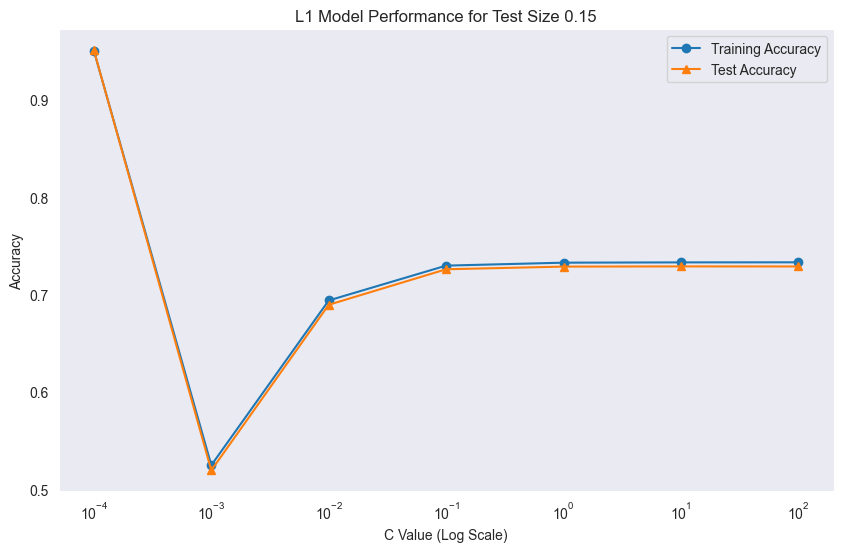

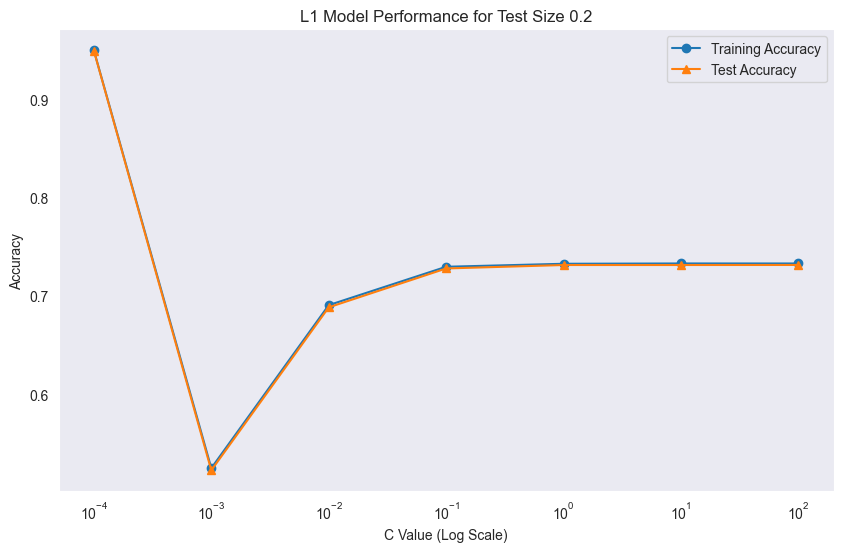

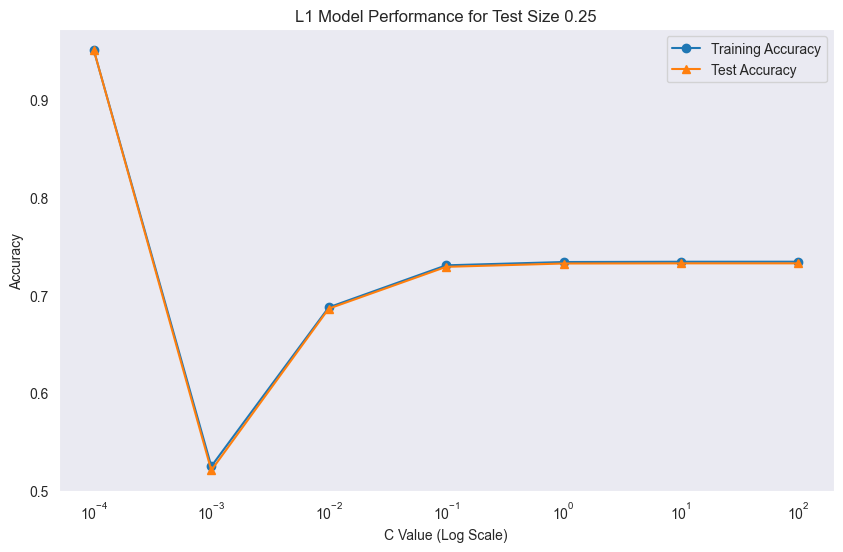

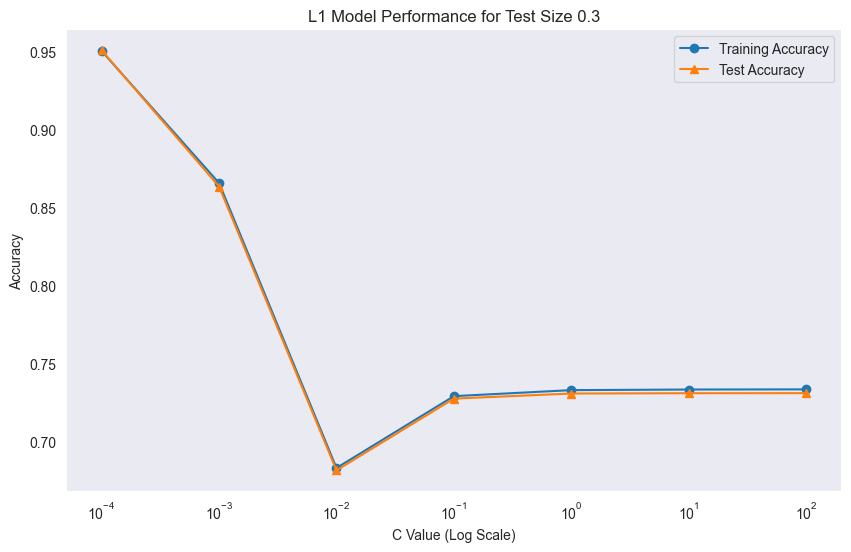

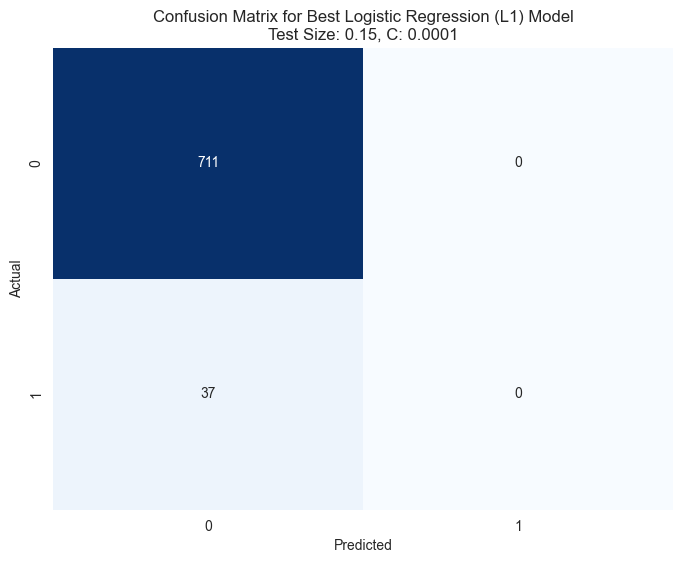


=== Confusion Matrix Values ===
[[711   0]
 [ 37   0]]


In [30]:
# Parameters
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# Only keeping the balanced weights approach
approaches = [
    {"name": "L1 Balanced Weights", "class_weight": "balanced"},
]

# A dictionary to store best models for each approach
best_models = {}

# Loop through each approach
for approach in approaches:
    print(f"\n=== Testing Approach: {approach['name']} ===")

    # To store all results
    results = []

    # Loop over test_size and C combinations
    for test_size in test_sizes:
        for C in C_values:
            metrics = {
                'train_accuracy': [],
                'test_accuracy': []
            }

            for random_state in random_states:
                # Step 1: Split into Train and Test
                X_train, X_test, y_train, y_test = train_test_split(
                    X, y, test_size=test_size, random_state=random_state, stratify=y
                )

                # Train logistic regression with balanced weights
                model = LogisticRegression(
                    C=C,
                    penalty='l1',  # Using L1 regularization
                    solver='liblinear',
                    class_weight=approach["class_weight"],
                    max_iter=1000
                )
                model.fit(X_train, y_train)

                # Record metrics
                metrics['train_accuracy'].append(model.score(X_train, y_train))
                metrics['test_accuracy'].append(model.score(X_test, y_test))

            # Save average metrics
            results.append({
                'Test Size': test_size,
                'C Value': C,
                'Avg Training Accuracy': np.mean(metrics['train_accuracy']),
                'Avg Test Accuracy': np.mean(metrics['test_accuracy'])
            })

    # Convert to DataFrame
    results_df = pd.DataFrame(results)

    # Find the best model based on test accuracy
    best_model_idx = results_df['Avg Test Accuracy'].idxmax()
    best_model = results_df.iloc[best_model_idx]

    print(f"\n=== Best Model for {approach['name']} ===")
    print(f"Test Size: {best_model['Test Size']}")
    print(f"C Value: {best_model['C Value']}")
    print(f"Avg Training Accuracy: {best_model['Avg Training Accuracy']:.6f}")
    print(f"Avg Test Accuracy: {best_model['Avg Test Accuracy']:.6f}")

    # Store best model configuration for this approach
    best_models[approach['name']] = best_model

    # Plot accuracy vs C value for each test size
    for test_size in test_sizes:
        subset = results_df[results_df['Test Size'] == test_size]
        plt.figure(figsize=(10, 6))
        plt.plot(subset['C Value'], subset['Avg Training Accuracy'], label='Training Accuracy', marker='o')
        plt.plot(subset['C Value'], subset['Avg Test Accuracy'], label='Test Accuracy', marker='^')
        plt.xscale('log')
        plt.xlabel('C Value (Log Scale)')
        plt.ylabel('Accuracy')
        plt.title(f'L1 Model Performance for Test Size {test_size}')
        plt.legend()
        plt.grid()
        plt.show()

# ================ CONFUSION MATRIX FOR BEST MODEL ================
# Now let's create the confusion matrix for the best model

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get the best model parameters
best_approach = list(best_models.keys())[0]  # Since there's only one approach
best_params = best_models[best_approach]
best_test_size = best_params['Test Size']
best_C = best_params['C Value']

# Create a final model with the best parameters
# Using a fixed random state for consistency
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=best_test_size, random_state=42, stratify=y
)

final_model = LogisticRegression(
    C=best_C,
    penalty='l1',
    solver='liblinear',
    class_weight="balanced",
    max_iter=1000
)
final_model.fit(X_train, y_train)

# Make predictions
y_pred = final_model.predict(X_test)

# Create and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix for Best Logistic Regression (L1) Model\nTest Size: {best_test_size}, C: {best_C}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\n=== Confusion Matrix Values ===")
print(cm)

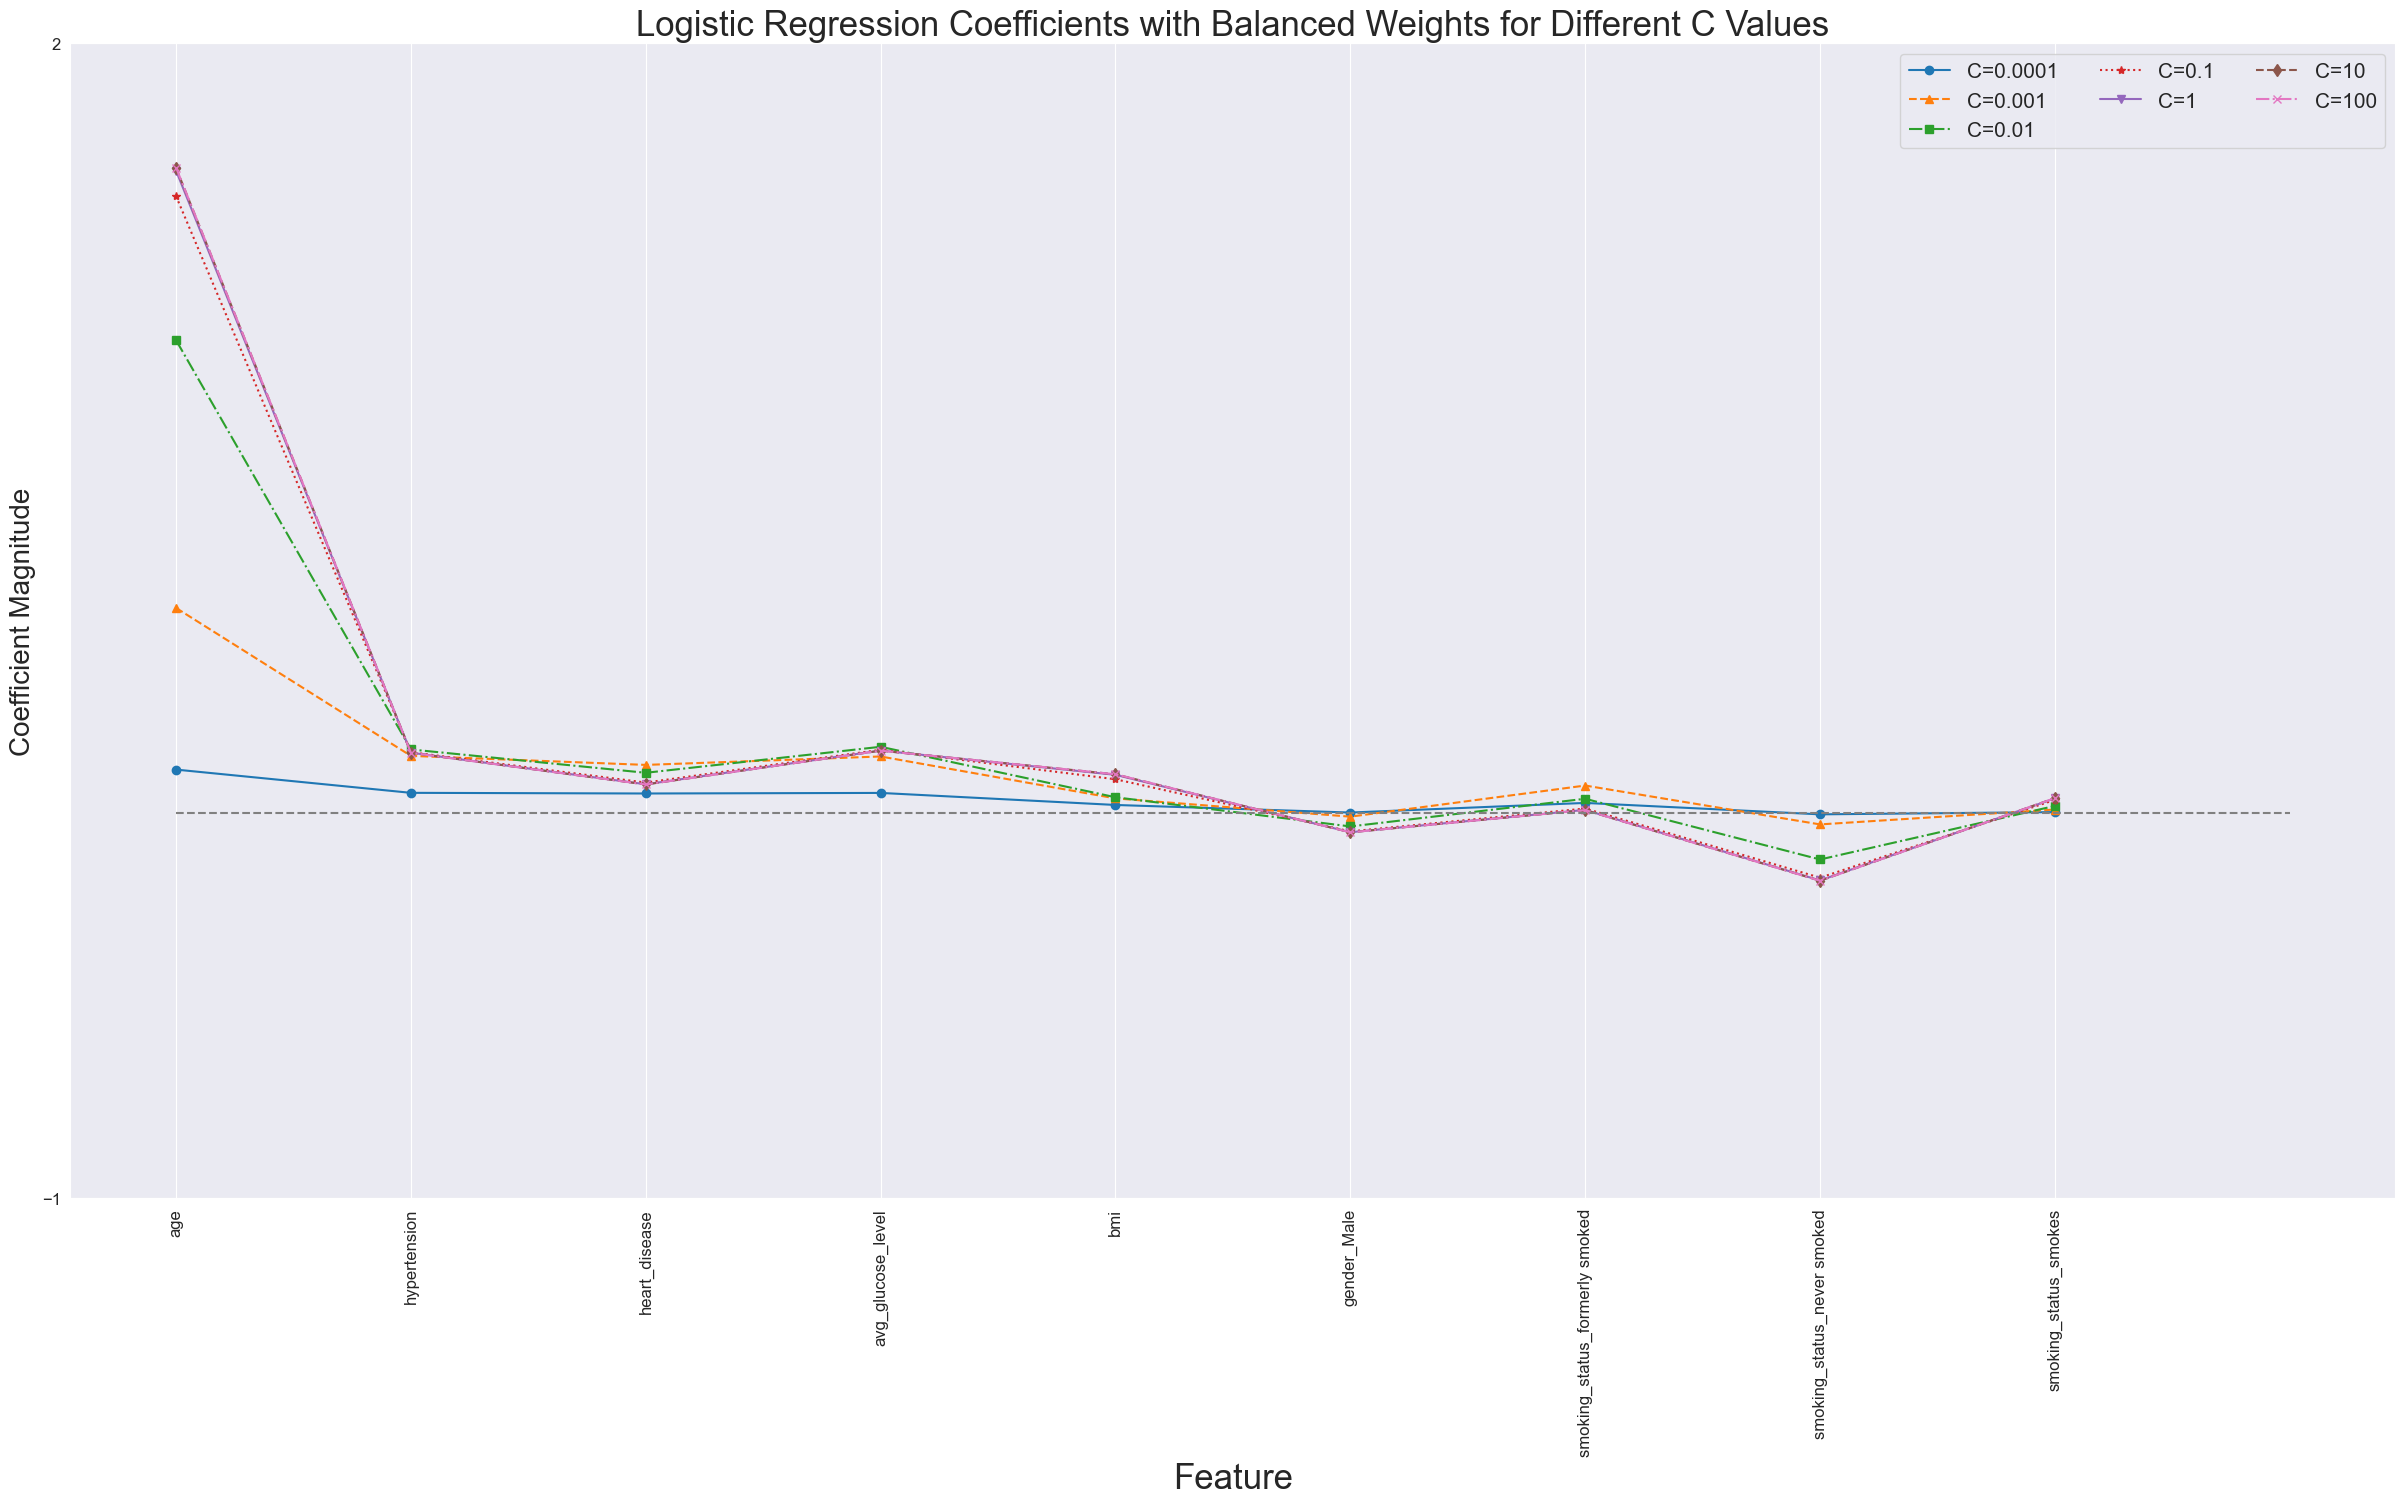

=== Top 5 Predictors (L2 Regularization with Balanced Weights) ===
1.  Feature: age
     Coefficient Weight: 1.677059
     Absolute Weight: 1.677059
     C Value: 100
2.  Feature: age
     Coefficient Weight: 1.676329
     Absolute Weight: 1.676329
     C Value: 10
3.  Feature: age
     Coefficient Weight: 1.669098
     Absolute Weight: 1.669098
     C Value: 1
4.  Feature: age
     Coefficient Weight: 1.602880
     Absolute Weight: 1.602880
     C Value: 0.1
5.  Feature: age
     Coefficient Weight: 1.228844
     Absolute Weight: 1.228844
     C Value: 0.01

=== Overall Top Predictor ===
Feature: age
Coefficient Weight of the Top Predictor: 1.677059
Absolute Weight of the Top Predictor: 1.677059
Best C Value for Top Predictor: 100

=== Comparing Weighted vs Non-Weighted Models ===


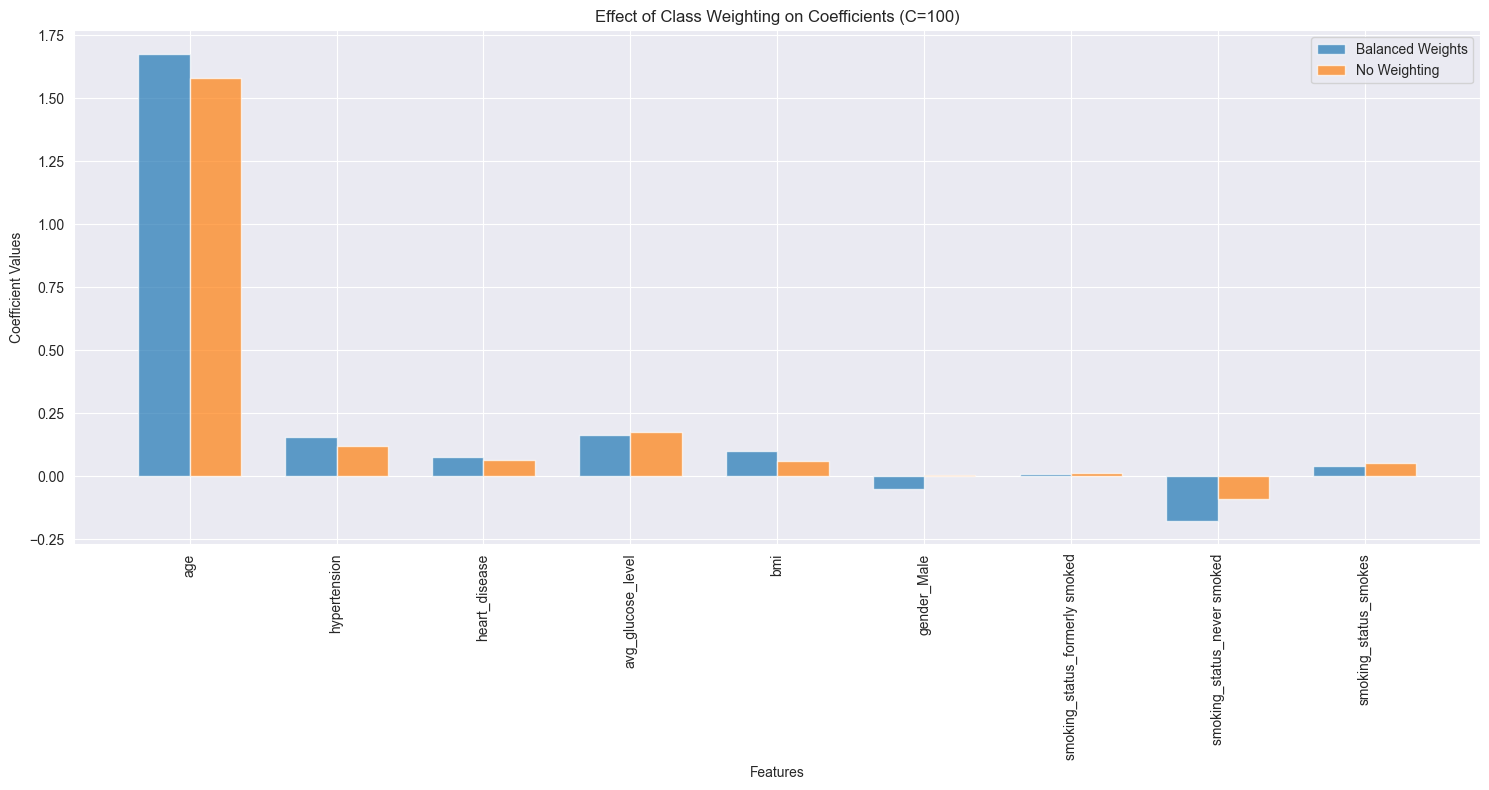

In [22]:
# Define target variable
target = "stroke"
X = df.drop(columns=[target])
y = df[target]

# Define all C values
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# Train models for all C values WITH balanced weights and store coefficients
models = {C: LogisticRegression(C=C, penalty='l2', solver="liblinear", class_weight="balanced").fit(X, y) for C in C_values}

# Create figure
fig = plt.figure(figsize=(30, 15))  # Larger figure for better visibility

# Line styles and markers for better differentiation
line_styles = ['-', '--', '-.', ':']
markers = ['o', '^', 's', '*', 'v', 'd', 'x', 'p']

for idx, (C, model) in enumerate(models.items()):
    plt.plot(model.coef_.T, f"{line_styles[idx % len(line_styles)]}{markers[idx % len(markers)]}", label=f"C={C}")

plt.xticks(range(X.shape[1]), X.columns, rotation=90, fontsize=12)  # Larger font size for readability
plt.hlines(0, 0, X.shape[1], colors='gray', linestyles='dashed')

# Adjust y-axis ticks with a step of 3
y_min, y_max = plt.ylim()
plt.yticks(np.arange(np.floor(y_min), np.ceil(y_max) + 1, 3), fontsize=12)

plt.xlabel("Feature", fontsize=25)
plt.ylabel("Coefficient Magnitude", fontsize=20)
plt.legend(loc='best', fontsize=15, ncol=3)
plt.title("Logistic Regression Coefficients with Balanced Weights for Different C Values", fontsize=25)
plt.grid(True)  # Adds a grid for better readability
plt.show()

# Find the top 5 predictors
top_predictors = []

for C, model in models.items():
    for idx, coef in enumerate(model.coef_[0]):
        top_predictors.append({
            "Feature": X.columns[idx],
            "Coefficient Weight": coef,
            "Absolute Weight": abs(coef),  # Store absolute weight
            "C Value": C
        })

# Sort predictors by absolute coefficient weight in descending order
top_predictors = sorted(top_predictors, key=lambda x: x["Absolute Weight"], reverse=True)

# Get the top 5 predictors
top_5_predictors = top_predictors[:5]

# Display the top 5 predictors
print("=== Top 5 Predictors (L2 Regularization with Balanced Weights) ===")
for i, predictor in enumerate(top_5_predictors, start=1):
    print(f"{i}.  Feature: {predictor['Feature']}")
    print(f"     Coefficient Weight: {predictor['Coefficient Weight']:.6f}")
    print(f"     Absolute Weight: {predictor['Absolute Weight']:.6f}")
    print(f"     C Value: {predictor['C Value']}")

# Display the overall top predictor
overall_top_predictor = top_5_predictors[0]
print("\n=== Overall Top Predictor ===")
print(f"Feature: {overall_top_predictor['Feature']}")
print(f"Coefficient Weight of the Top Predictor: {overall_top_predictor['Coefficient Weight']:.6f}")
print(f"Absolute Weight of the Top Predictor: {overall_top_predictor['Absolute Weight']:.6f}")
print(f"Best C Value for Top Predictor: {overall_top_predictor['C Value']}")

# Optional additional analysis: Compare weighted vs non-weighted coefficients
print("\n=== Comparing Weighted vs Non-Weighted Models ===")
# Train a non-weighted model using the best C value
best_C = overall_top_predictor['C Value']
weighted_model = models[best_C]
non_weighted_model = LogisticRegression(C=best_C, penalty='l2', solver="liblinear").fit(X, y)

# Plot comparison
plt.figure(figsize=(15, 8))
bar_width = 0.35
index = np.arange(X.shape[1])

plt.bar(index, weighted_model.coef_[0], bar_width, label='Balanced Weights', alpha=0.7)
plt.bar(index + bar_width, non_weighted_model.coef_[0], bar_width, label='No Weighting', alpha=0.7)

plt.xlabel('Features')
plt.ylabel('Coefficient Values')
plt.title(f'Effect of Class Weighting on Coefficients (C={best_C})')
plt.xticks(index + bar_width/2, X.columns, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

#### Support Vector Machine (SVM)
For the Linear SVM model with L1 or L2 regularization, we are employing class weight balancing to address the dataset imbalance. Since Linear SVM supports class weights, this approach helps the model give more importance to the minority class (stroke cases) during training without altering the data distribution. This improves the model’s ability to correctly predict underrepresented cases while still benefiting from regularization to prevent overfitting.

#### SVM L1

=== Best Models for Each Test Size ===
 Test Size  C Value  Avg Training Accuracy  Avg Test Accuracy
0.15       0.0001   0.950638               0.947794          
0.20       0.0001   0.950866               0.947593          
0.25       0.0001   0.950562               0.949157          
0.30       0.0001   0.950359               0.949866          


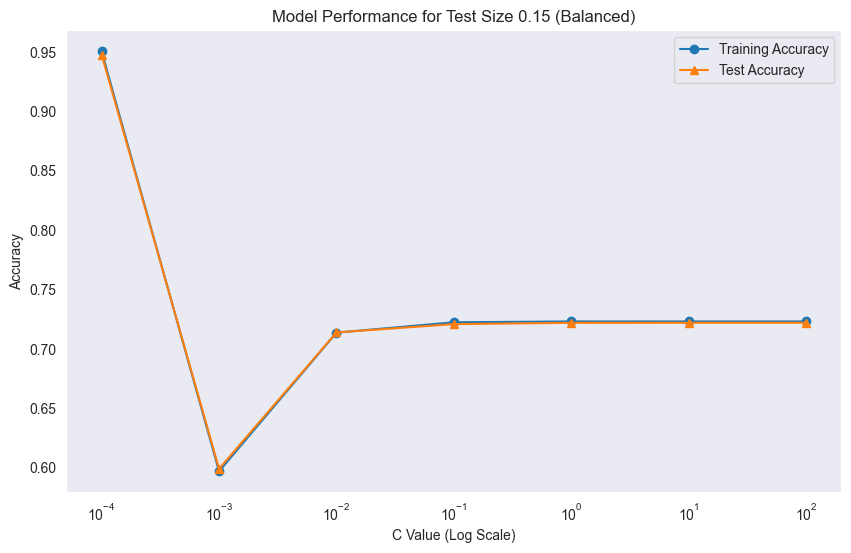

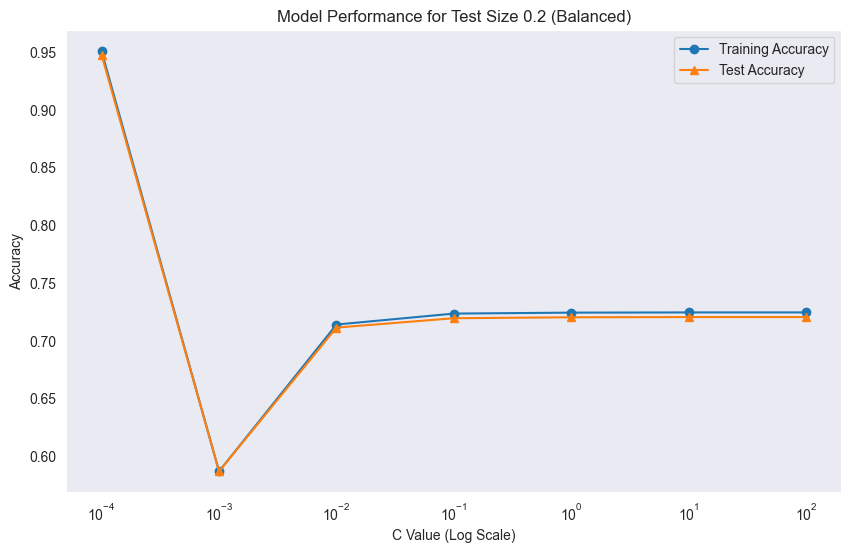

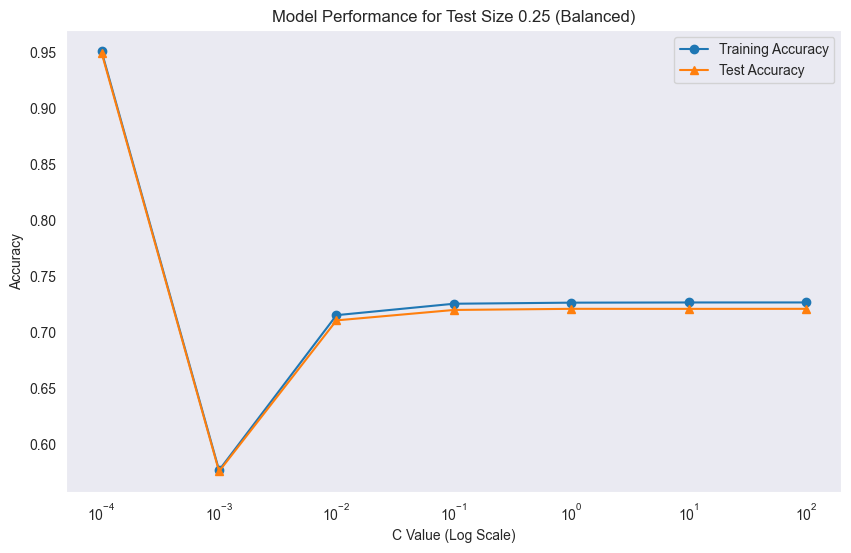

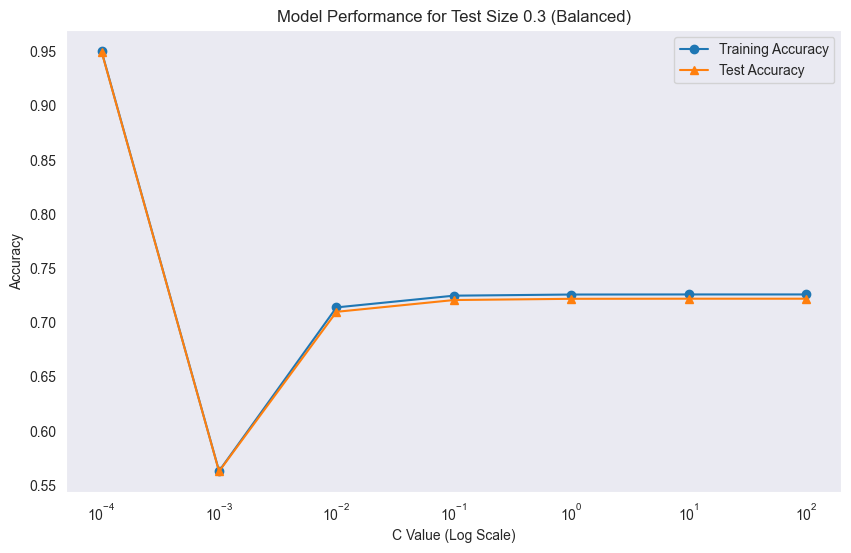


=== Best Average Model Overall for SVM L1 (Balanced) ===
Test Size : 0.30
Average Training Accuracy : 0.950359
Average Test Accuracy : 0.949866
C parameter : 0.0001


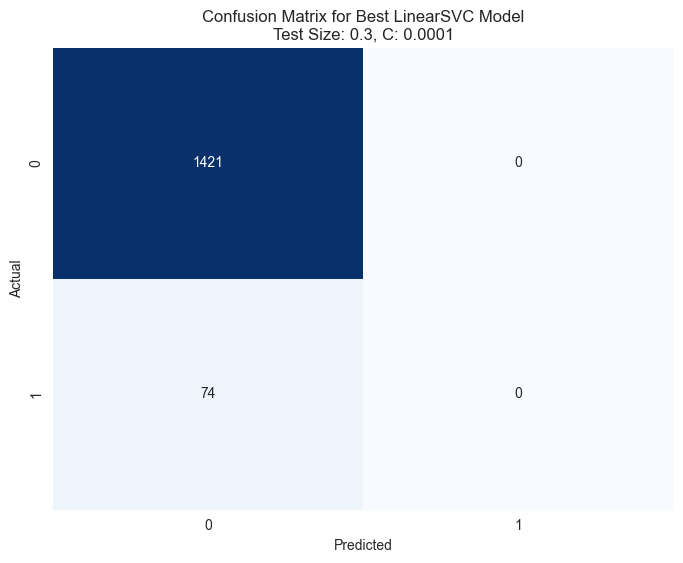


=== Confusion Matrix Values ===
[[1421    0]
 [  74    0]]


In [28]:
# Parameters
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# To store all results
results = []

# Loop over test_size and C combinations
for test_size in test_sizes:
    for C in C_values:
        train_accuracies = []
        test_accuracies = []

        for random_state in random_states:
            # Step 1: Split into Train and Temp
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=random_state
            )

            # Train logistic regression with class weight balancing
            model = LinearSVC(C=C, penalty='l1', loss='squared_hinge', dual=False, class_weight='balanced')
            model.fit(X_train, y_train)

            # Record accuracies
            train_accuracies.append(model.score(X_train, y_train))
            test_accuracies.append(model.score(X_test, y_test))

        # Save average result
        results.append({
            'Test Size': test_size,
            'C Value': C,
            'Avg Training Accuracy': sum(train_accuracies) / len(train_accuracies),
            'Avg Test Accuracy': sum(test_accuracies) / len(test_accuracies)
        })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Find the best model for each test size based on the highest Avg Test Accuracy
best_models_per_test_size = results_df.loc[results_df.groupby('Test Size')['Avg Test Accuracy'].idxmax()]

# Identify the best model overall
best_model_overall = best_models_per_test_size.loc[best_models_per_test_size['Avg Test Accuracy'].idxmax()]

# Display best models for each test size
print("=== Best Models for Each Test Size ===")
print(best_models_per_test_size.to_string(index=False, header=True, justify="left"))

# Plot for each test size
for test_size in test_sizes:
    subset = results_df[results_df['Test Size'] == test_size]
    plt.figure(figsize=(10, 6))
    plt.plot(subset['C Value'], subset['Avg Training Accuracy'], label='Training Accuracy', marker='o')
    plt.plot(subset['C Value'], subset['Avg Test Accuracy'], label='Test Accuracy', marker='^')
    plt.xscale('log')
    plt.xlabel('C Value (Log Scale)')
    plt.ylabel('Accuracy')
    plt.title(f'Model Performance for Test Size {test_size} (Balanced)')
    plt.legend()
    plt.grid()
    plt.show()

# Display the best average model overall
print("\n=== Best Average Model Overall for SVM L1 (Balanced) ===")
print(f"Test Size : {best_model_overall['Test Size']:.2f}")
print(f"Average Training Accuracy : {best_model_overall['Avg Training Accuracy']:.6f}")
print(f"Average Test Accuracy : {best_model_overall['Avg Test Accuracy']:.6f}")
print(f"C parameter : {best_model_overall['C Value']}")

# ================ CONFUSION MATRIX FOR BEST MODEL ================
# Now let's create the confusion matrix for the best model

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get the best model parameters
best_test_size = best_model_overall['Test Size']
best_C = best_model_overall['C Value']

# Create a final model with the best parameters using a fixed random state for consistency
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=best_test_size, random_state=42, stratify=y
)

# Train the final model
final_model = LinearSVC(
    C=best_C,
    penalty='l1',
    loss='squared_hinge',
    dual=False,
    class_weight='balanced'
)
final_model.fit(X_train, y_train)

# Make predictions
y_pred = final_model.predict(X_test)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix for Best LinearSVC Model\nTest Size: {best_test_size}, C: {best_C}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\n=== Confusion Matrix Values ===")
print(cm)

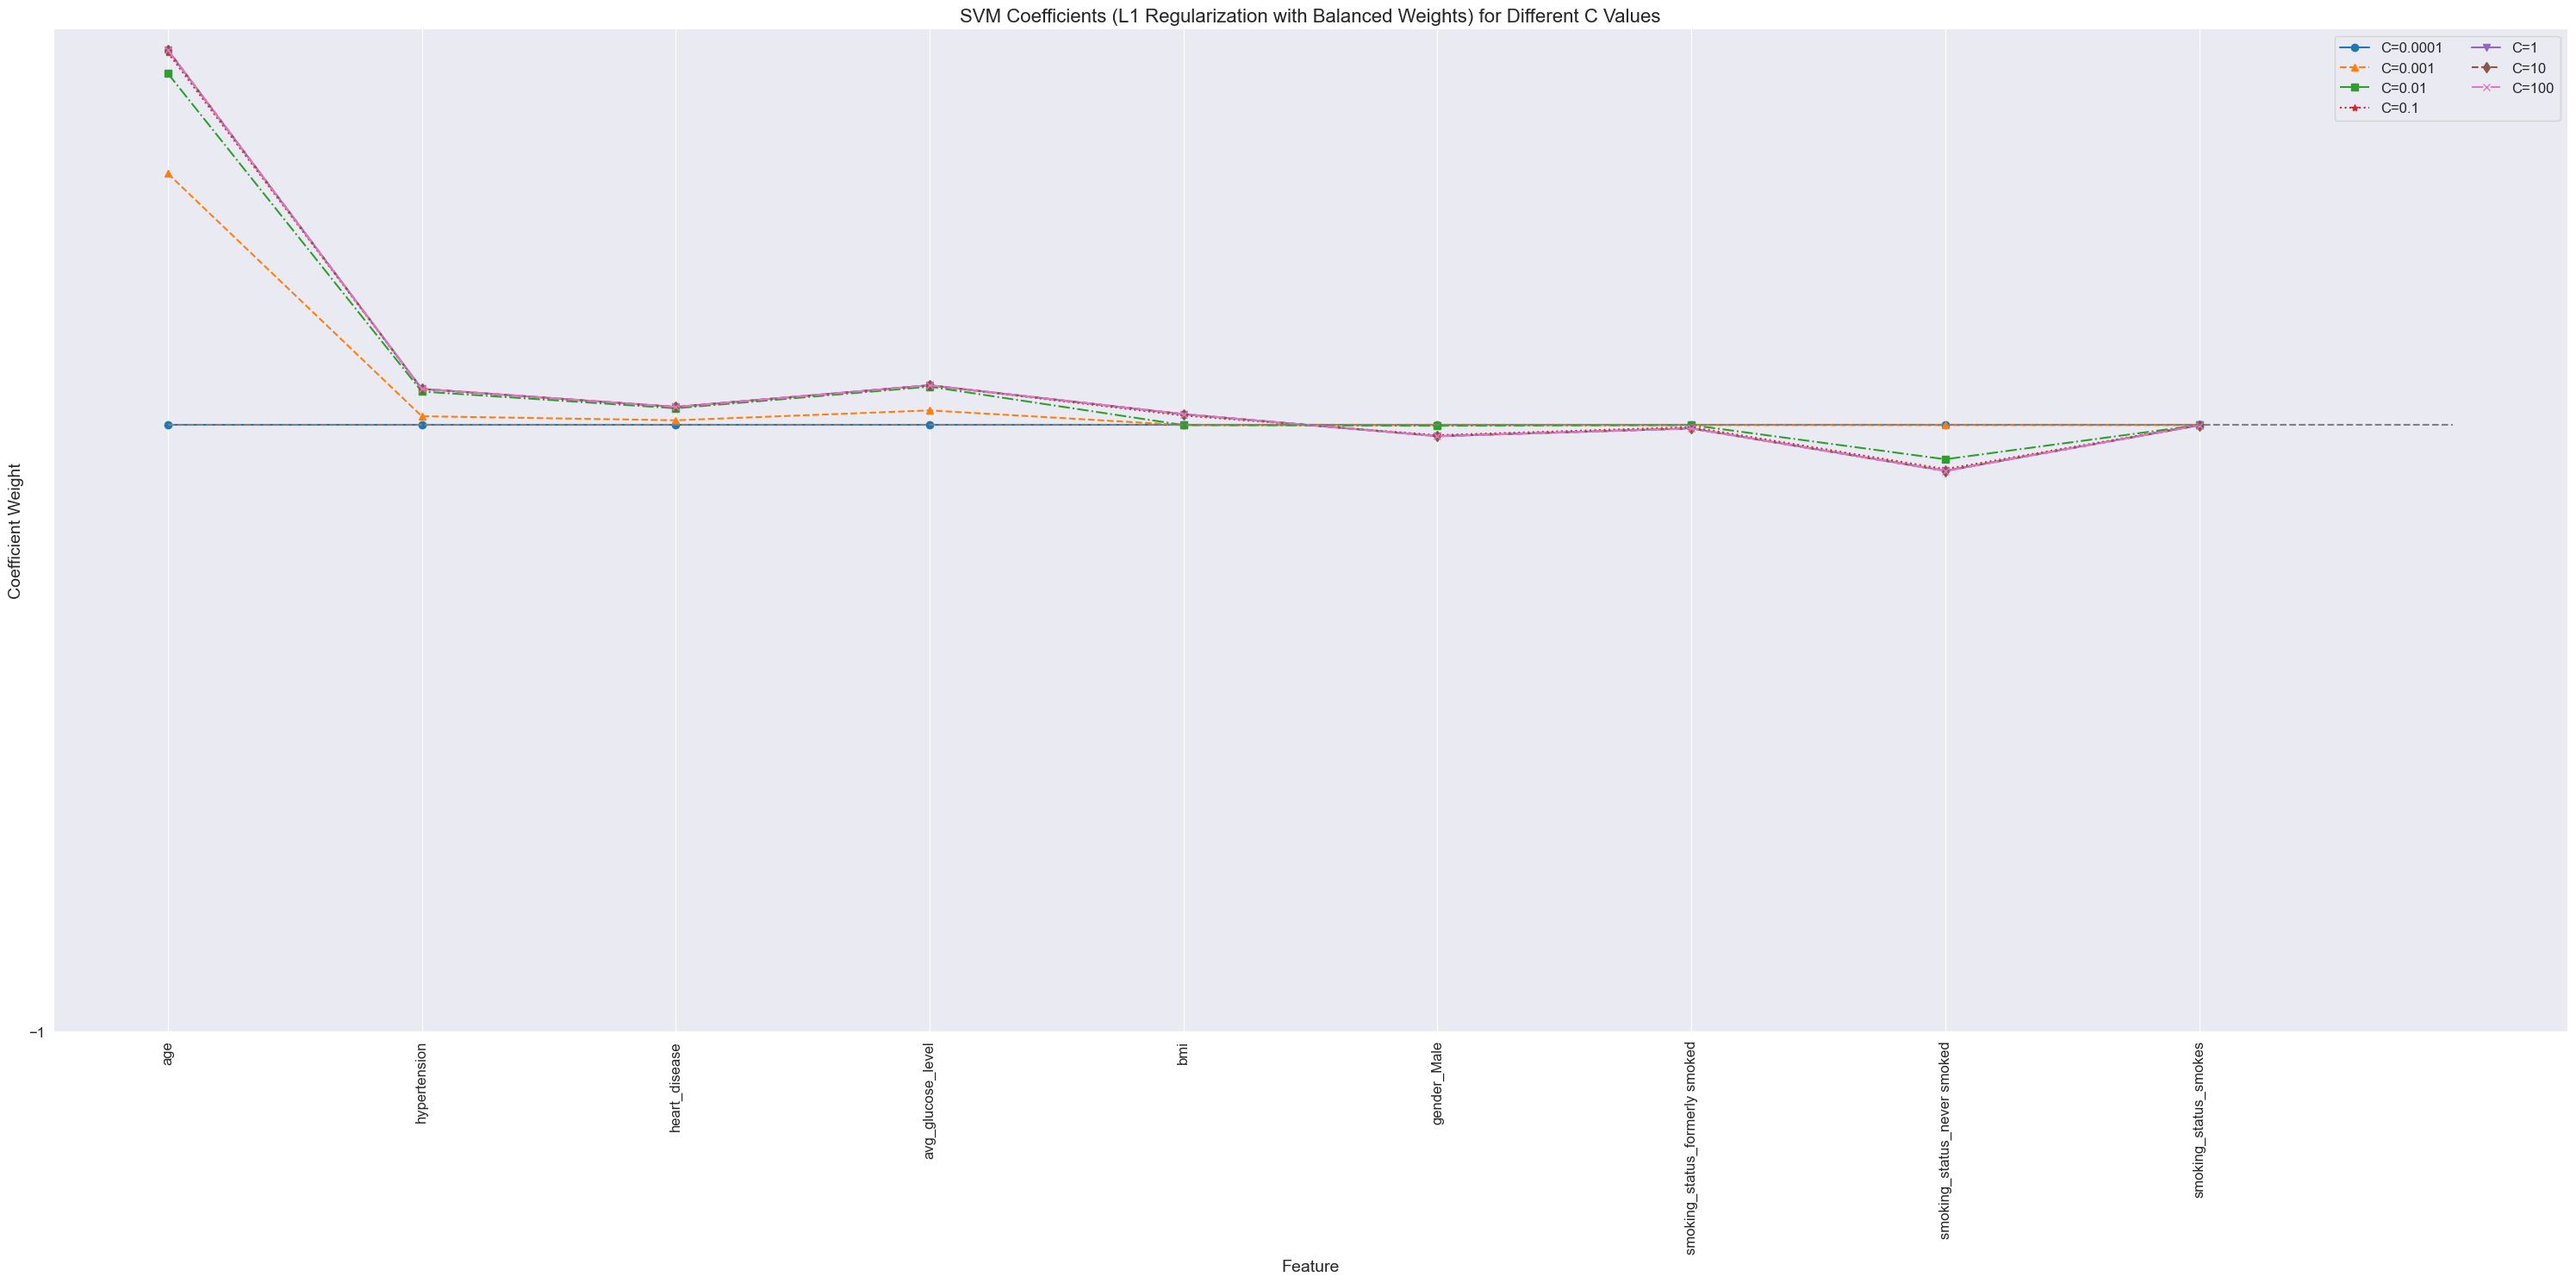

=== Top 5 Predictors (SVM L1 Regularization with Balanced Weights) ===
1.  Feature: age
     Coefficient Weight: 0.618551
     Absolute Weight: 0.618551
     C Value: 100.0
2.  Feature: age
     Coefficient Weight: 0.618512
     Absolute Weight: 0.618512
     C Value: 10.0
3.  Feature: age
     Coefficient Weight: 0.618124
     Absolute Weight: 0.618124
     C Value: 1.0
4.  Feature: age
     Coefficient Weight: 0.613922
     Absolute Weight: 0.613922
     C Value: 0.1
5.  Feature: age
     Coefficient Weight: 0.579518
     Absolute Weight: 0.579518
     C Value: 0.01

=== Overall Top Predictor ===
Feature: age
Coefficient Weight: 0.618551
Absolute Weight: 0.618551
C Value: 100.0

=== Comparing Weighted vs Non-Weighted Models ===


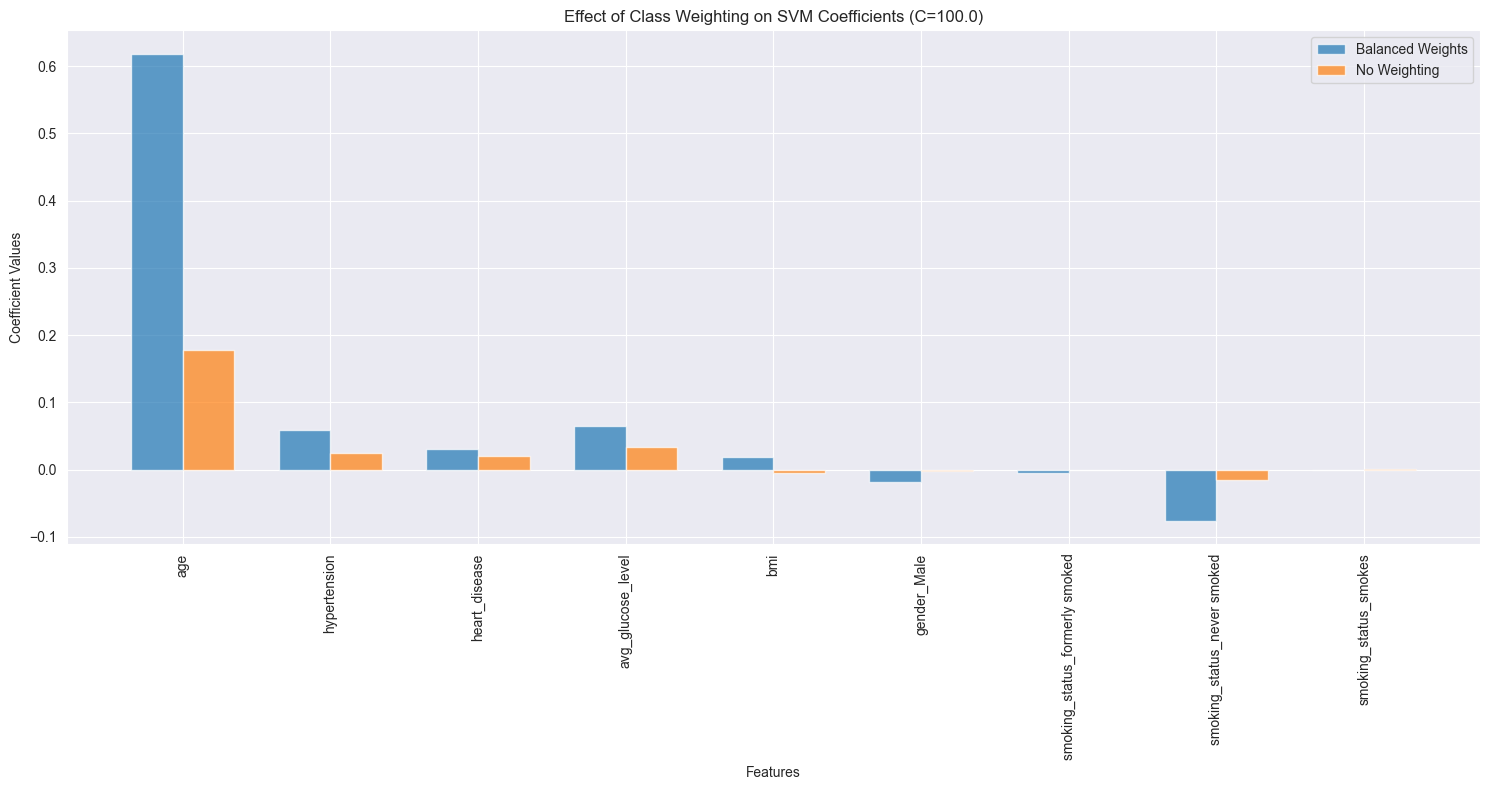

In [24]:
# Store trained models and top predictors
models = {}
all_predictors = []

# Train LinearSVC models for each C value with balanced class weights
for C in C_values:
    model = LinearSVC(C=C, penalty="l1", dual=False, max_iter=10000, class_weight="balanced")
    model.fit(X, y)
    models[C] = model

    # Extract non-zero coefficients
    for idx, coef in enumerate(model.coef_[0]):
        if coef != 0:
            all_predictors.append({
                "Feature": X.columns[idx],
                "Coefficient Weight": coef,
                "Absolute Weight": abs(coef),
                "C Value": C
            })

# Visualization
fig = plt.figure(figsize=(30, 15))
line_styles = ['-', '--', '-.', ':']
markers = ['o', '^', 's', '*', 'v', 'd', 'x', 'p']

for idx, (C, model) in enumerate(models.items()):
    plt.plot(
        np.arange(0, X.shape[1] * 10, 10),  # Spread x-axis
        model.coef_[0],
        f"{line_styles[idx % len(line_styles)]}{markers[idx % len(markers)]}",
        label=f"C={C}"
    )

plt.xticks(
    ticks=np.arange(0, X.shape[1] * 10, 10),
    labels=X.columns,
    rotation=90,
    fontsize=12
)
plt.hlines(0, xmin=0, xmax=X.shape[1] * 10, colors='gray', linestyles='dashed')

y_min, y_max = plt.ylim()
plt.yticks(np.arange(np.floor(y_min), np.ceil(y_max) + 1, 10), fontsize=12)

plt.xlabel("Feature", fontsize=14)
plt.ylabel("Coefficient Weight", fontsize=14)
plt.title("SVM Coefficients (L1 Regularization with Balanced Weights) for Different C Values", fontsize=16)
plt.legend(loc="best", fontsize=12, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

# Create DataFrame for predictor analysis
predictors_df = pd.DataFrame(all_predictors)

# Sort predictors by absolute weight
sorted_predictors = predictors_df.sort_values(by='Absolute Weight', ascending=False)

# Top 5 predictors
top_5_predictors = sorted_predictors.head(5)

print("=== Top 5 Predictors (SVM L1 Regularization with Balanced Weights) ===")
for i, (_, row) in enumerate(top_5_predictors.iterrows(), start=1):
    print(f"{i}.  Feature: {row['Feature']}")
    print(f"     Coefficient Weight: {row['Coefficient Weight']:.6f}")
    print(f"     Absolute Weight: {row['Absolute Weight']:.6f}")
    print(f"     C Value: {row['C Value']}")

# Overall top predictor
overall_top_predictor = sorted_predictors.iloc[0]
print("\n=== Overall Top Predictor ===")
print(f"Feature: {overall_top_predictor['Feature']}")
print(f"Coefficient Weight: {overall_top_predictor['Coefficient Weight']:.6f}")
print(f"Absolute Weight: {overall_top_predictor['Absolute Weight']:.6f}")
print(f"C Value: {overall_top_predictor['C Value']}")

# Optional: Add comparison between weighted and non-weighted models
print("\n=== Comparing Weighted vs Non-Weighted Models ===")
# Get the best C value
best_C = overall_top_predictor['C Value']

# Train models with and without class weighting
weighted_model = LinearSVC(C=best_C, penalty="l1", dual=False, max_iter=10000, class_weight="balanced")
weighted_model.fit(X, y)

non_weighted_model = LinearSVC(C=best_C, penalty="l1", dual=False, max_iter=10000)
non_weighted_model.fit(X, y)

# Plot comparison
plt.figure(figsize=(15, 8))
bar_width = 0.35
index = np.arange(X.shape[1])

plt.bar(index, weighted_model.coef_[0], bar_width, label='Balanced Weights', alpha=0.7)
plt.bar(index + bar_width, non_weighted_model.coef_[0], bar_width, label='No Weighting', alpha=0.7)

plt.xlabel('Features')
plt.ylabel('Coefficient Values')
plt.title(f'Effect of Class Weighting on SVM Coefficients (C={best_C})')
plt.xticks(index + bar_width/2, X.columns, rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

### SVM L2

=== Best Models for Each Test Size (Balanced) ===
 Test Size  C Value  Avg Training Accuracy  Avg Test Accuracy
0.15        1.0     0.723175               0.722059          
0.20       10.0     0.724849               0.720812          
0.25       10.0     0.726479               0.720787          
0.30        1.0     0.725961               0.722074          


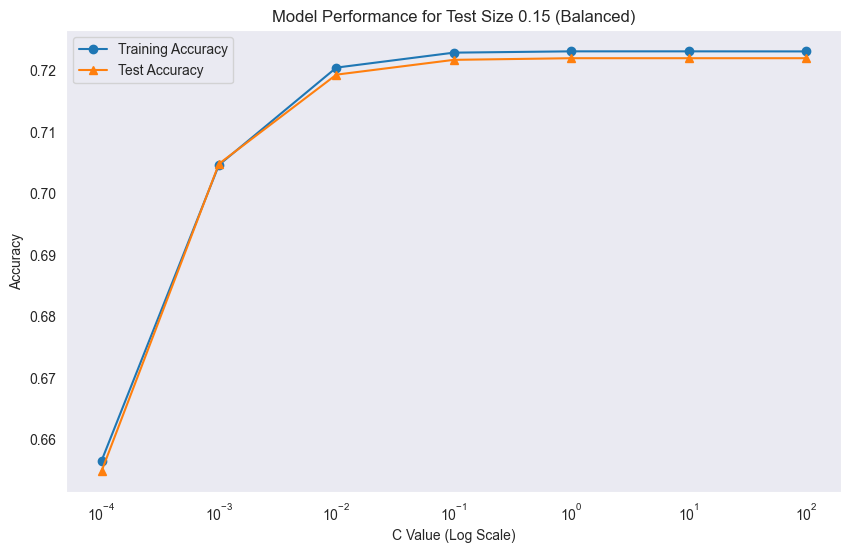

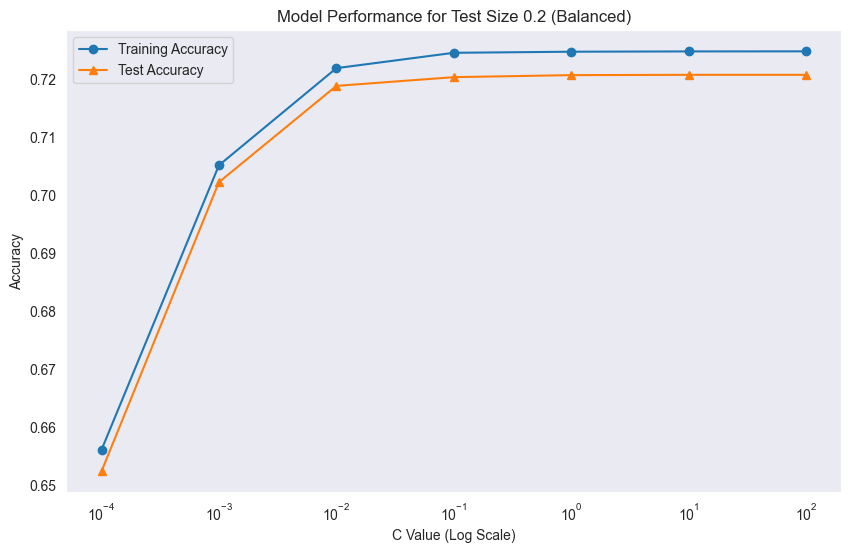

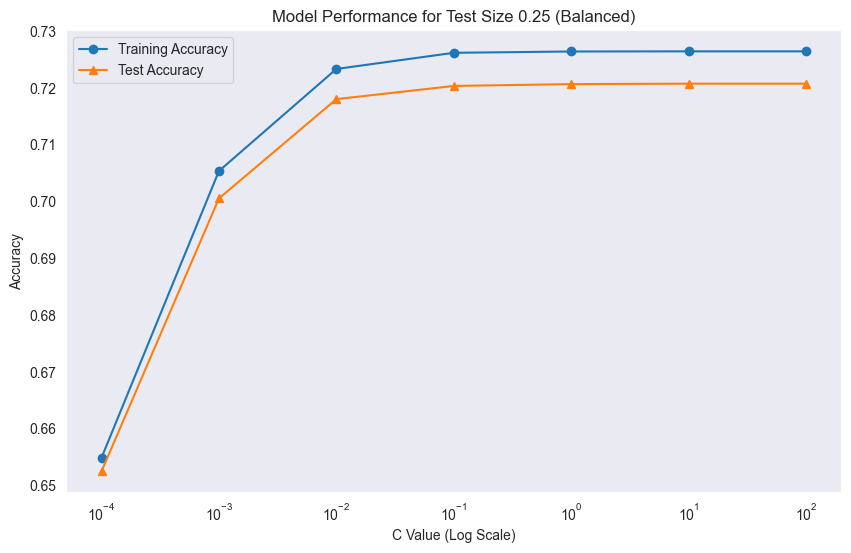

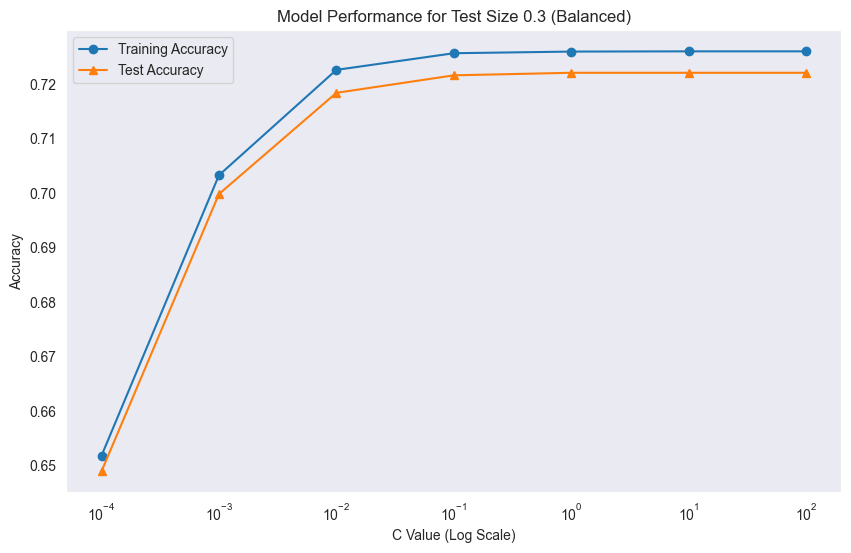


=== Best Average Model Overall for SVM L2 (Balanced) ===
Test Size : 0.30
Average Training Accuracy : 0.725961
Average Test Accuracy : 0.722074
C parameter : 1.0


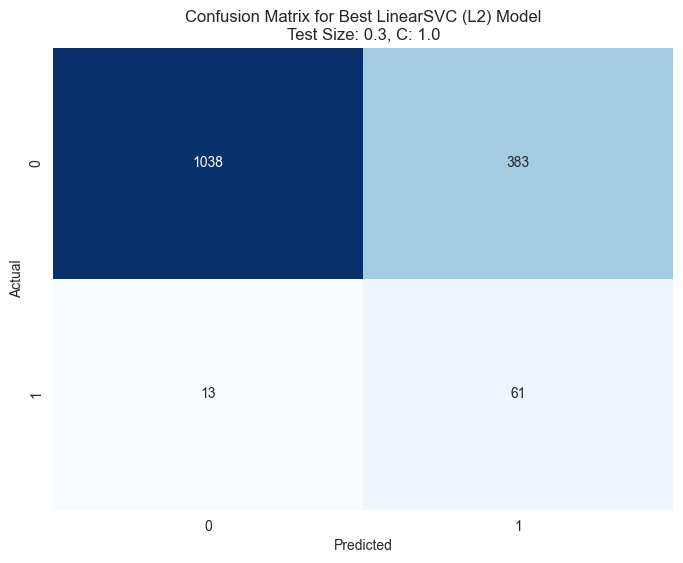


=== Confusion Matrix Values ===
[[1038  383]
 [  13   61]]


In [29]:
# Parameters
test_sizes = [0.15, 0.2, 0.25, 0.3]
random_states = range(1, 21)
C_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# To store all results
results = []

# Loop over test_size and C combinations
for test_size in test_sizes:
    for C in C_values:
        train_accuracies = []
        test_accuracies = []
        
        for random_state in random_states:
            # Step 1: Split into Train and Temp
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=test_size, random_state=random_state
            )
            
            # Train logistic regression with balanced class weights
            model = LinearSVC(C=C, penalty='l2', loss='squared_hinge', dual=False, class_weight='balanced')
            model.fit(X_train, y_train)

            # Record accuracies
            train_accuracies.append(model.score(X_train, y_train))
            test_accuracies.append(model.score(X_test, y_test))

        # Save average result
        results.append({
            'Test Size': test_size,
            'C Value': C,
            'Avg Training Accuracy': sum(train_accuracies) / len(train_accuracies),
            'Avg Test Accuracy': sum(test_accuracies) / len(test_accuracies),
        })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Find the best model for each test size based on the highest Avg Test Accuracy
best_models_per_test_size = results_df.loc[results_df.groupby('Test Size')['Avg Test Accuracy'].idxmax()]

# Identify the best model overall
best_model_overall = best_models_per_test_size.loc[best_models_per_test_size['Avg Test Accuracy'].idxmax()]

# Display best models for each test size
print("=== Best Models for Each Test Size (Balanced) ===")
print(best_models_per_test_size.to_string(index=False, header=True, justify="left"))

# Plot for each test size
for test_size in test_sizes:
    subset = results_df[results_df['Test Size'] == test_size]
    plt.figure(figsize=(10, 6))
    plt.plot(subset['C Value'], subset['Avg Training Accuracy'], label='Training Accuracy', marker='o')
    plt.plot(subset['C Value'], subset['Avg Test Accuracy'], label='Test Accuracy', marker='^')
    plt.xscale('log')
    plt.xlabel('C Value (Log Scale)')
    plt.ylabel('Accuracy')
    plt.title(f'Model Performance for Test Size {test_size} (Balanced)')
    plt.legend()
    plt.grid()
    plt.show()

# Display the best average model overall
print("\n=== Best Average Model Overall for SVM L2 (Balanced) ===")
print(f"Test Size : {best_model_overall['Test Size']:.2f}")
print(f"Average Training Accuracy : {best_model_overall['Avg Training Accuracy']:.6f}")
print(f"Average Test Accuracy : {best_model_overall['Avg Test Accuracy']:.6f}")
print(f"C parameter : {best_model_overall['C Value']}")

# ================ CONFUSION MATRIX FOR BEST MODEL ================
# Now let's create the confusion matrix for the best model

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get the best model parameters
best_test_size = best_model_overall['Test Size']
best_C = best_model_overall['C Value']

# Create a final model with the best parameters using a fixed random state for consistency
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=best_test_size, random_state=42, stratify=y
)

# Train the final model
final_model = LinearSVC(
    C=best_C,
    penalty='l2',
    loss='squared_hinge',
    dual=False,
    class_weight='balanced'
)
final_model.fit(X_train, y_train)

# Make predictions
y_pred = final_model.predict(X_test)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix for Best LinearSVC (L2) Model\nTest Size: {best_test_size}, C: {best_C}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\n=== Confusion Matrix Values ===")
print(cm)

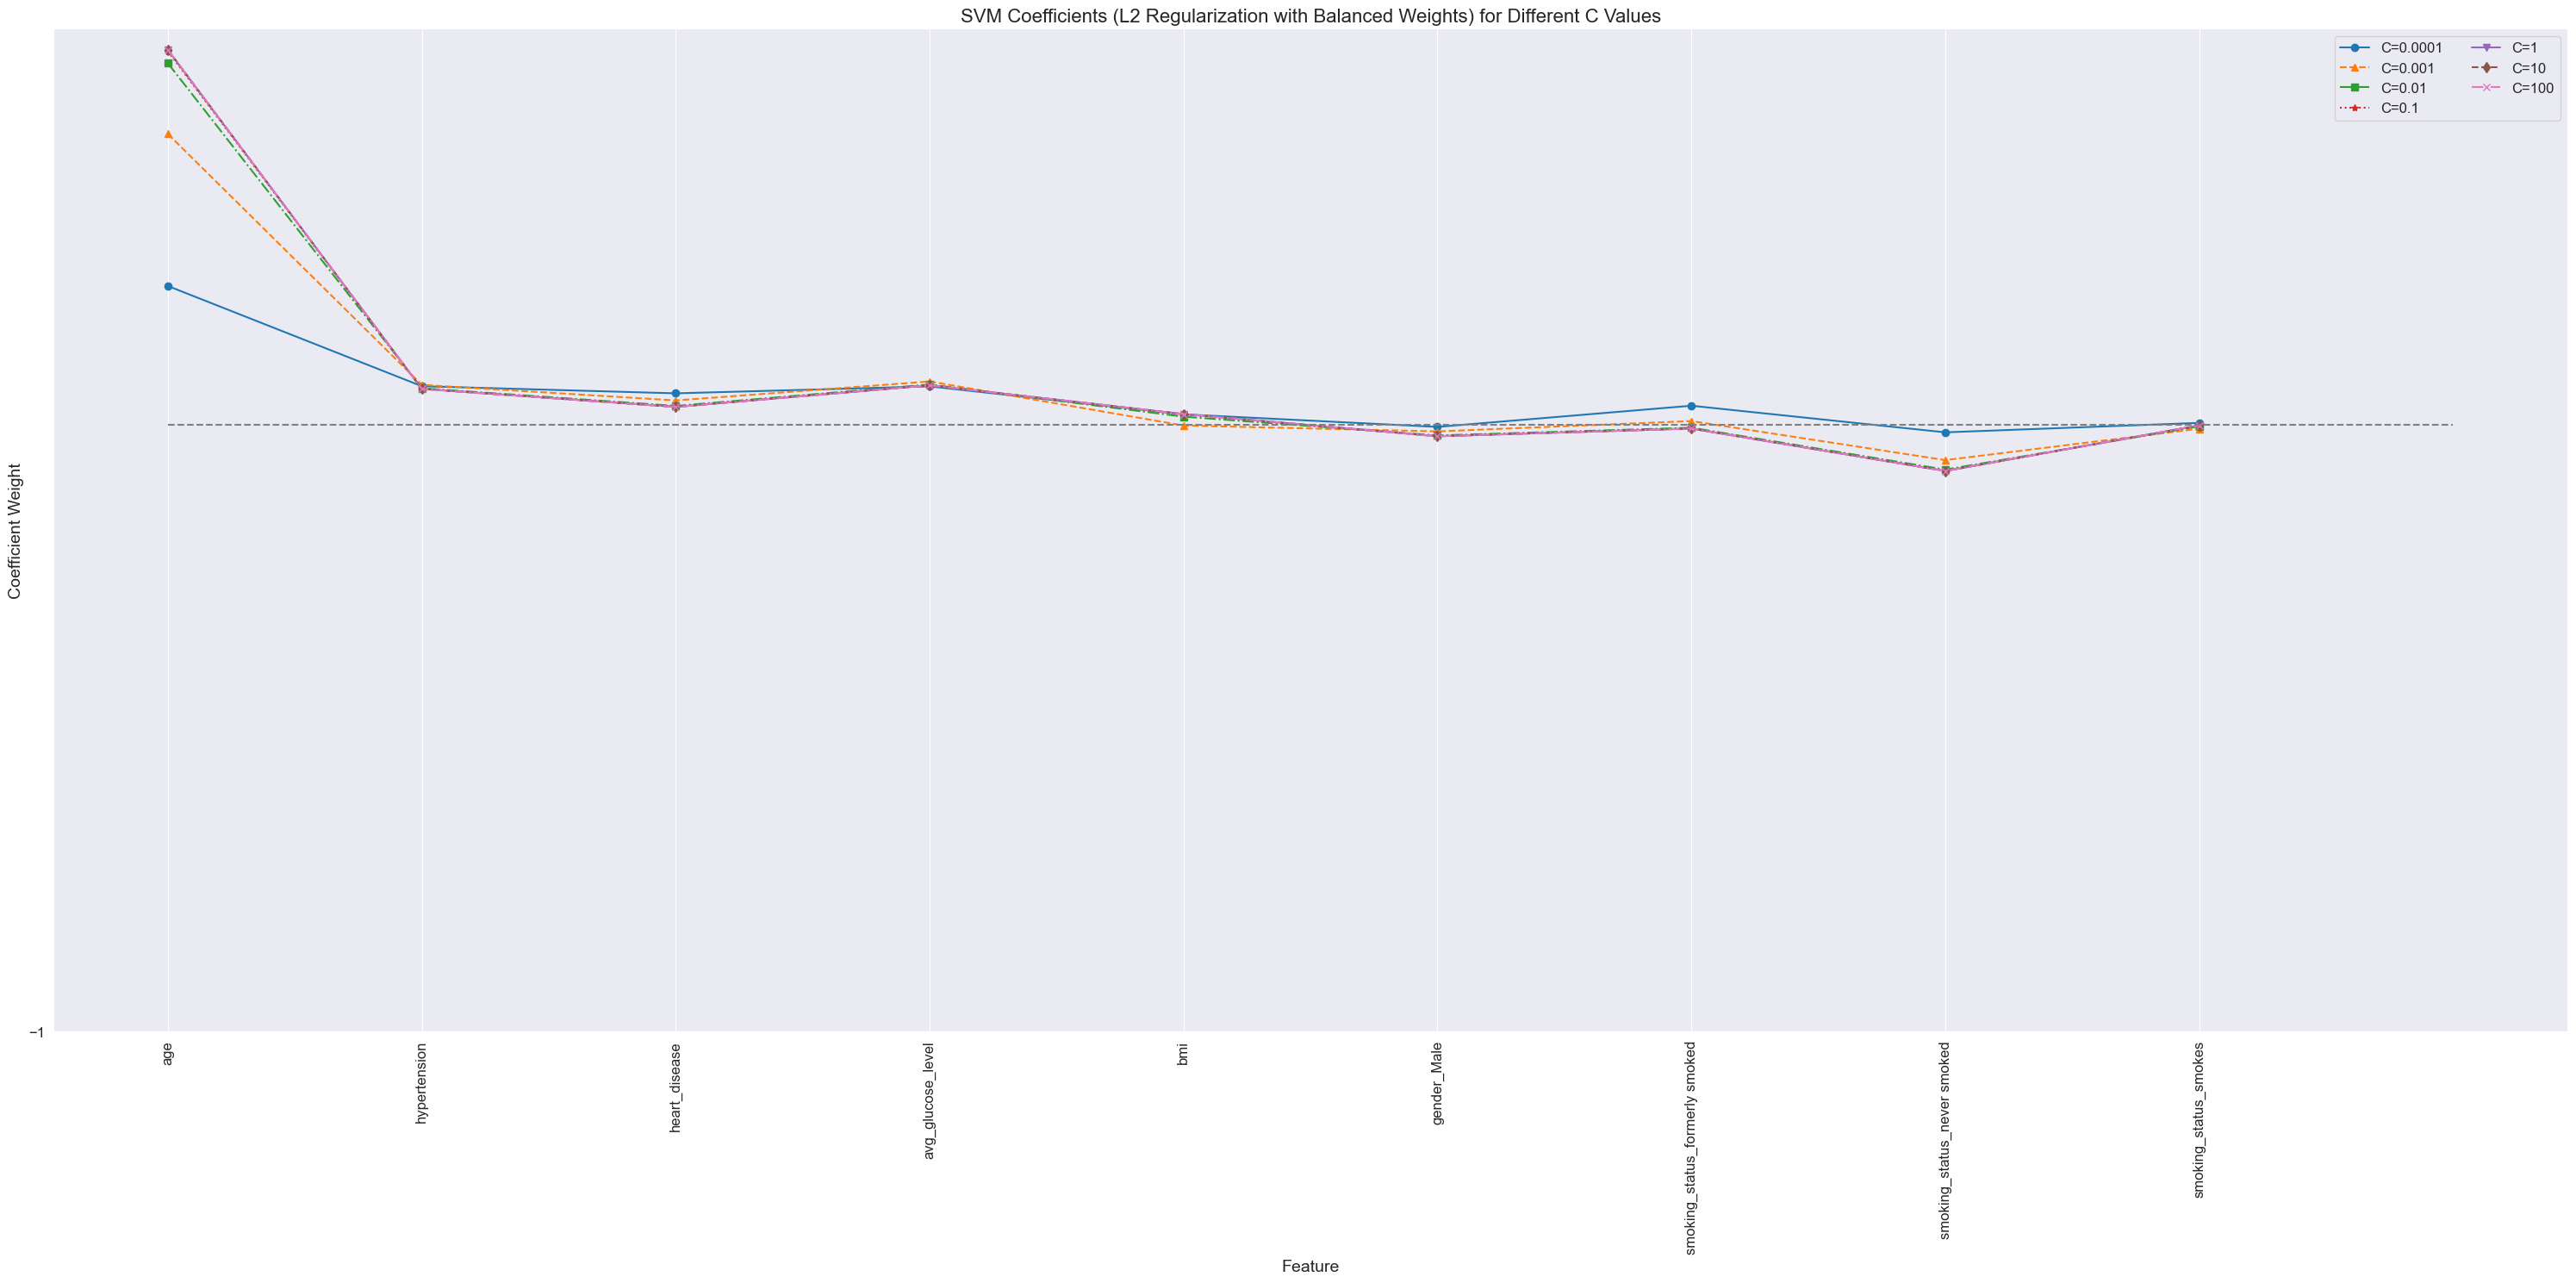

=== Top 5 Predictors (SVM L2 Regularization with Balanced Weights) ===
1.  Feature: age
     Coefficient Weight: 0.618555
     Absolute Weight: 0.618555
     C Value: 100.0
2.  Feature: age
     Coefficient Weight: 0.618534
     Absolute Weight: 0.618534
     C Value: 10.0
3.  Feature: age
     Coefficient Weight: 0.618320
     Absolute Weight: 0.618320
     C Value: 1.0
4.  Feature: age
     Coefficient Weight: 0.616198
     Absolute Weight: 0.616198
     C Value: 0.1
5.  Feature: age
     Coefficient Weight: 0.596466
     Absolute Weight: 0.596466
     C Value: 0.01

=== Overall Top Predictor ===
Feature: age
Coefficient Weight: 0.618555
Absolute Weight: 0.618555
C Value: 100.0


In [26]:
models = {}
all_predictors = []

# Train LinearSVC models for each C value with balanced class weights
for C in C_values:
    model = LinearSVC(C=C, penalty="l2", dual=False, max_iter=10000, class_weight="balanced")
    model.fit(X, y)
    models[C] = model

    # Extract non-zero coefficients
    for idx, coef in enumerate(model.coef_[0]):
        if coef != 0:
            all_predictors.append({
                "Feature": X.columns[idx],
                "Coefficient Weight": coef,
                "Absolute Weight": abs(coef),
                "C Value": C
            })

# Visualization of coefficients across different C values
fig = plt.figure(figsize=(30, 15))  # Larger figure for better visibility
line_styles = ['-', '--', '-.', ':']
markers = ['o', '^', 's', '*', 'v', 'd', 'x', 'p']

# Plot each model's coefficients
for idx, (C, model) in enumerate(models.items()):
    plt.plot(
        np.arange(0, X.shape[1] * 10, 10),  # Spread x-axis by a factor of 10
        model.coef_[0],
        f"{line_styles[idx % len(line_styles)]}{markers[idx % len(markers)]}",
        label=f"C={C}"
    )

# Customize plot ticks and labels
plt.xticks(
    ticks=np.arange(0, X.shape[1] * 10, 10),
    labels=X.columns,
    rotation=90,
    fontsize=12
)
plt.hlines(0, xmin=0, xmax=X.shape[1] * 10, colors='gray', linestyles='dashed')

# Adjust y-axis ticks
y_min, y_max = plt.ylim()
plt.yticks(np.arange(np.floor(y_min), np.ceil(y_max) + 1, 3), fontsize=12)

# Add labels and title
plt.xlabel("Feature", fontsize=14)
plt.ylabel("Coefficient Weight", fontsize=14)
plt.title("SVM Coefficients (L2 Regularization with Balanced Weights) for Different C Values", fontsize=16)
plt.legend(loc="best", fontsize=12, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()

# Create DataFrame for predictor analysis
predictors_df = pd.DataFrame(all_predictors)

# Sort predictors by absolute weight
sorted_predictors = predictors_df.sort_values(by='Absolute Weight', ascending=False)

# Get the top 5 predictors
top_5_predictors = sorted_predictors.head(5)

print("=== Top 5 Predictors (SVM L2 Regularization with Balanced Weights) ===")
for i, (_, row) in enumerate(top_5_predictors.iterrows(), start=1):
    print(f"{i}.  Feature: {row['Feature']}")
    print(f"     Coefficient Weight: {row['Coefficient Weight']:.6f}")
    print(f"     Absolute Weight: {row['Absolute Weight']:.6f}")
    print(f"     C Value: {row['C Value']}")

# Get the overall top predictor
overall_top_predictor = sorted_predictors.iloc[0]

print("\n=== Overall Top Predictor ===")
print(f"Feature: {overall_top_predictor['Feature']}")
print(f"Coefficient Weight: {overall_top_predictor['Coefficient Weight']:.6f}")
print(f"Absolute Weight: {overall_top_predictor['Absolute Weight']:.6f}")
print(f"C Value: {overall_top_predictor['C Value']}")

### Summary of Results
| Machine Learning Method | Train Accuracy | Test Accuracy | Best Parameter | Top Predictor Variable |
| :---: |:--------------:|:-------------:|:--------------:| :---: |
| kNN |      96%       |      94%      | N_Neighbor = 7 | N/A |
| Logistic (L2) |      73%       |      73%      |       10       | age |
| Logistic (L1) |      95%       |      95%      |     0.0001     | age |
| Linear SVM (L1) |      95%       |      95%      |     0.0001     | age|
| Linear SVM (L2) |      73%       |      72%      |       1        | age |

The table shows that kNN and L1-regularized models (Logistic and Linear SVM) achieve the highest train and test accuracies at 95%, while L2-regularized models perform significantly worse, with accuracies around 72–73%. Despite these high accuracy values, they are likely misleading due to class imbalance, as accuracy does not reflect performance on the minority class. All models except kNN identify "age" as the top predictor, highlighting its strong influence.